# Introducción a los Modelos de Regresión Lineal

Los modelos de regresión se utilizan para poder generar relaciones entre uno o más variables explicativas con una o más variables de respuesta. Existen diferentes tipo de modelos de regresión, yendo de los más particulares y complejos a los más sencillos podemos encontrar (Junto a como usarlas en python):
- **Deep Neural Networks**: https://pytorch.org/
- **Gradient Boosting Models**: https://lightgbm.readthedocs.io/en/stable/
- **Gaussian Process Regression**: https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html#sklearn.gaussian_process.GaussianProcessRegressor
- **Regression Trees**: https://scikit-learn.org/stable/auto_examples/tree/plot_tree_regression.html
- **Linear Regression**: El cual veremos ahora, que existen MUCHAS implementaciones de este modelo.

Para abrir con GoogleColab:<a target="_blank" href="https://githubtocolab.com/SysBioengLab/IIQ3402-Statistical-Design/blob/main/Ayudantias/Ayudantia6_IntroModelosDeRegresion.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


Este tipo de modelos se pueden definir como: Dado una variable explicativa $\mathbf{x}\in \mathbb{R}^n$ queremos encontrar una función $f: \mathbb{R}^n \to \mathbb{R}^m$ tal que $f(\mathbf{x}) = \mathbf{y}$ donde $y\in \mathbb{R}^m$. 

El modelo más sencillo que logra poder encontrar este tipo de relaciones es la **regresión lineal**. Este tipo de modelos se basan en la siguiente ecuación:
$$
y_i = \mathbf{b} \mathbf{x}_i + b_0 \quad \forall i 
$$

Es decir, la función $f$ que teníamos previamente busca predecir $y_i$ por medio de la combinación lineal de los componentes de $\mathbf{x}_i$. Donde i corresponde a una observación de nuestro set de datos.

# Regresión lineal simple

La regresión lineal simple es la forma más sencilla de una regresión lineal, en esta se busca relacionar una variable explicativa con una de respuesta mediante la ponderación de la variable explicativa más una constante. O en forma matemática.
$$
y_i = \beta_1 x_i + \beta_0 \quad \forall i
$$

Así, nuestra variable explicativa se relaciona de forma lineal con nuestra variable de respuesta. 


Muchas veces, los datos no calzan perfectamente con un modelo de este estilo debido al ruido en el sistema. Así, muchas veces se utiliza la siguiente forma del modelo para poder modeloar este tipo de relaciones.
$$
Y \sim \mathcal{N}(\mu_Y =  \beta_1 x +  \beta_0, \sigma ^ 2)
$$
Así, la variable $Y$ es una variable aleatoria centrada en la regresión lineal y con una varianza $\sigma^2$. Para simplicidad, este modelo también puede ser denotado como
$$
y = \beta_1 x + \beta_0 + \varepsilon
$$
Donde $\varepsilon \sim N(0, \sigma ^2)$. Así, $\varepsilon$ captura el ruido/error del sistema.

Ahora nuestro trabajo viene en saber como estimar los parámetros de la regresión lineal simple.

# VideoJuegos (Ahora con Regresión)

Para poder entender mejor los modelos de regresión, evaluaremos el dataset de VideoJuegos `Video_Game_Sales_as_of_Jan_2017.csv`.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def read_course_dataset(name):
    """Carga un dataset desde el repositorio del curso en GitHub."""
    link = 'https://github.com/SysBioengLab/IIQ3402-Statistical-Design/blob/main/SetDeDatos/'
    link += name + '?raw=true'
    df = pd.read_csv(link)
    if 'Unnamed: 0' in df.columns:
        df = df.drop('Unnamed: 0', axis=1)
    return df

data = read_course_dataset('Video_Game_Sales_as_of_Jan_2017.csv')


## 1.

Realice la visualización de datos del dataset https://github.com/SysBioengLab/IIQ3402-Statistical-Design/blob/main/SetDeDatos/Video_Game_Sales_as_of_Jan_2017.csv ¿Qué variables poseen asociaciones lineales entre sí?

Una manera sencilla de evaluar si existen relaciones lineales entre datos es realizar la matriz de correlación.

Primero hay que evaluar cuales son las variables numéricas, de forma que el calculo de la covarianza sea eficiente.

In [34]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 17416 entries, 0 to 17415
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             17416 non-null  str    
 1   Platform         17416 non-null  str    
 2   Year_of_Release  17408 non-null  float64
 3   Genre            17416 non-null  str    
 4   Publisher        17415 non-null  str    
 5   NA_Sales         17416 non-null  float64
 6   EU_Sales         17416 non-null  float64
 7   JP_Sales         17416 non-null  float64
 8   Other_Sales      17416 non-null  float64
 9   Global_Sales     17416 non-null  float64
 10  Critic_Score     8336 non-null   float64
 11  Critic_Count     8336 non-null   float64
 12  User_Score       7798 non-null   float64
 13  User_Count       7798 non-null   float64
 14  Rating           10252 non-null  str    
dtypes: float64(10), str(5)
memory usage: 2.0 MB


<Axes: >

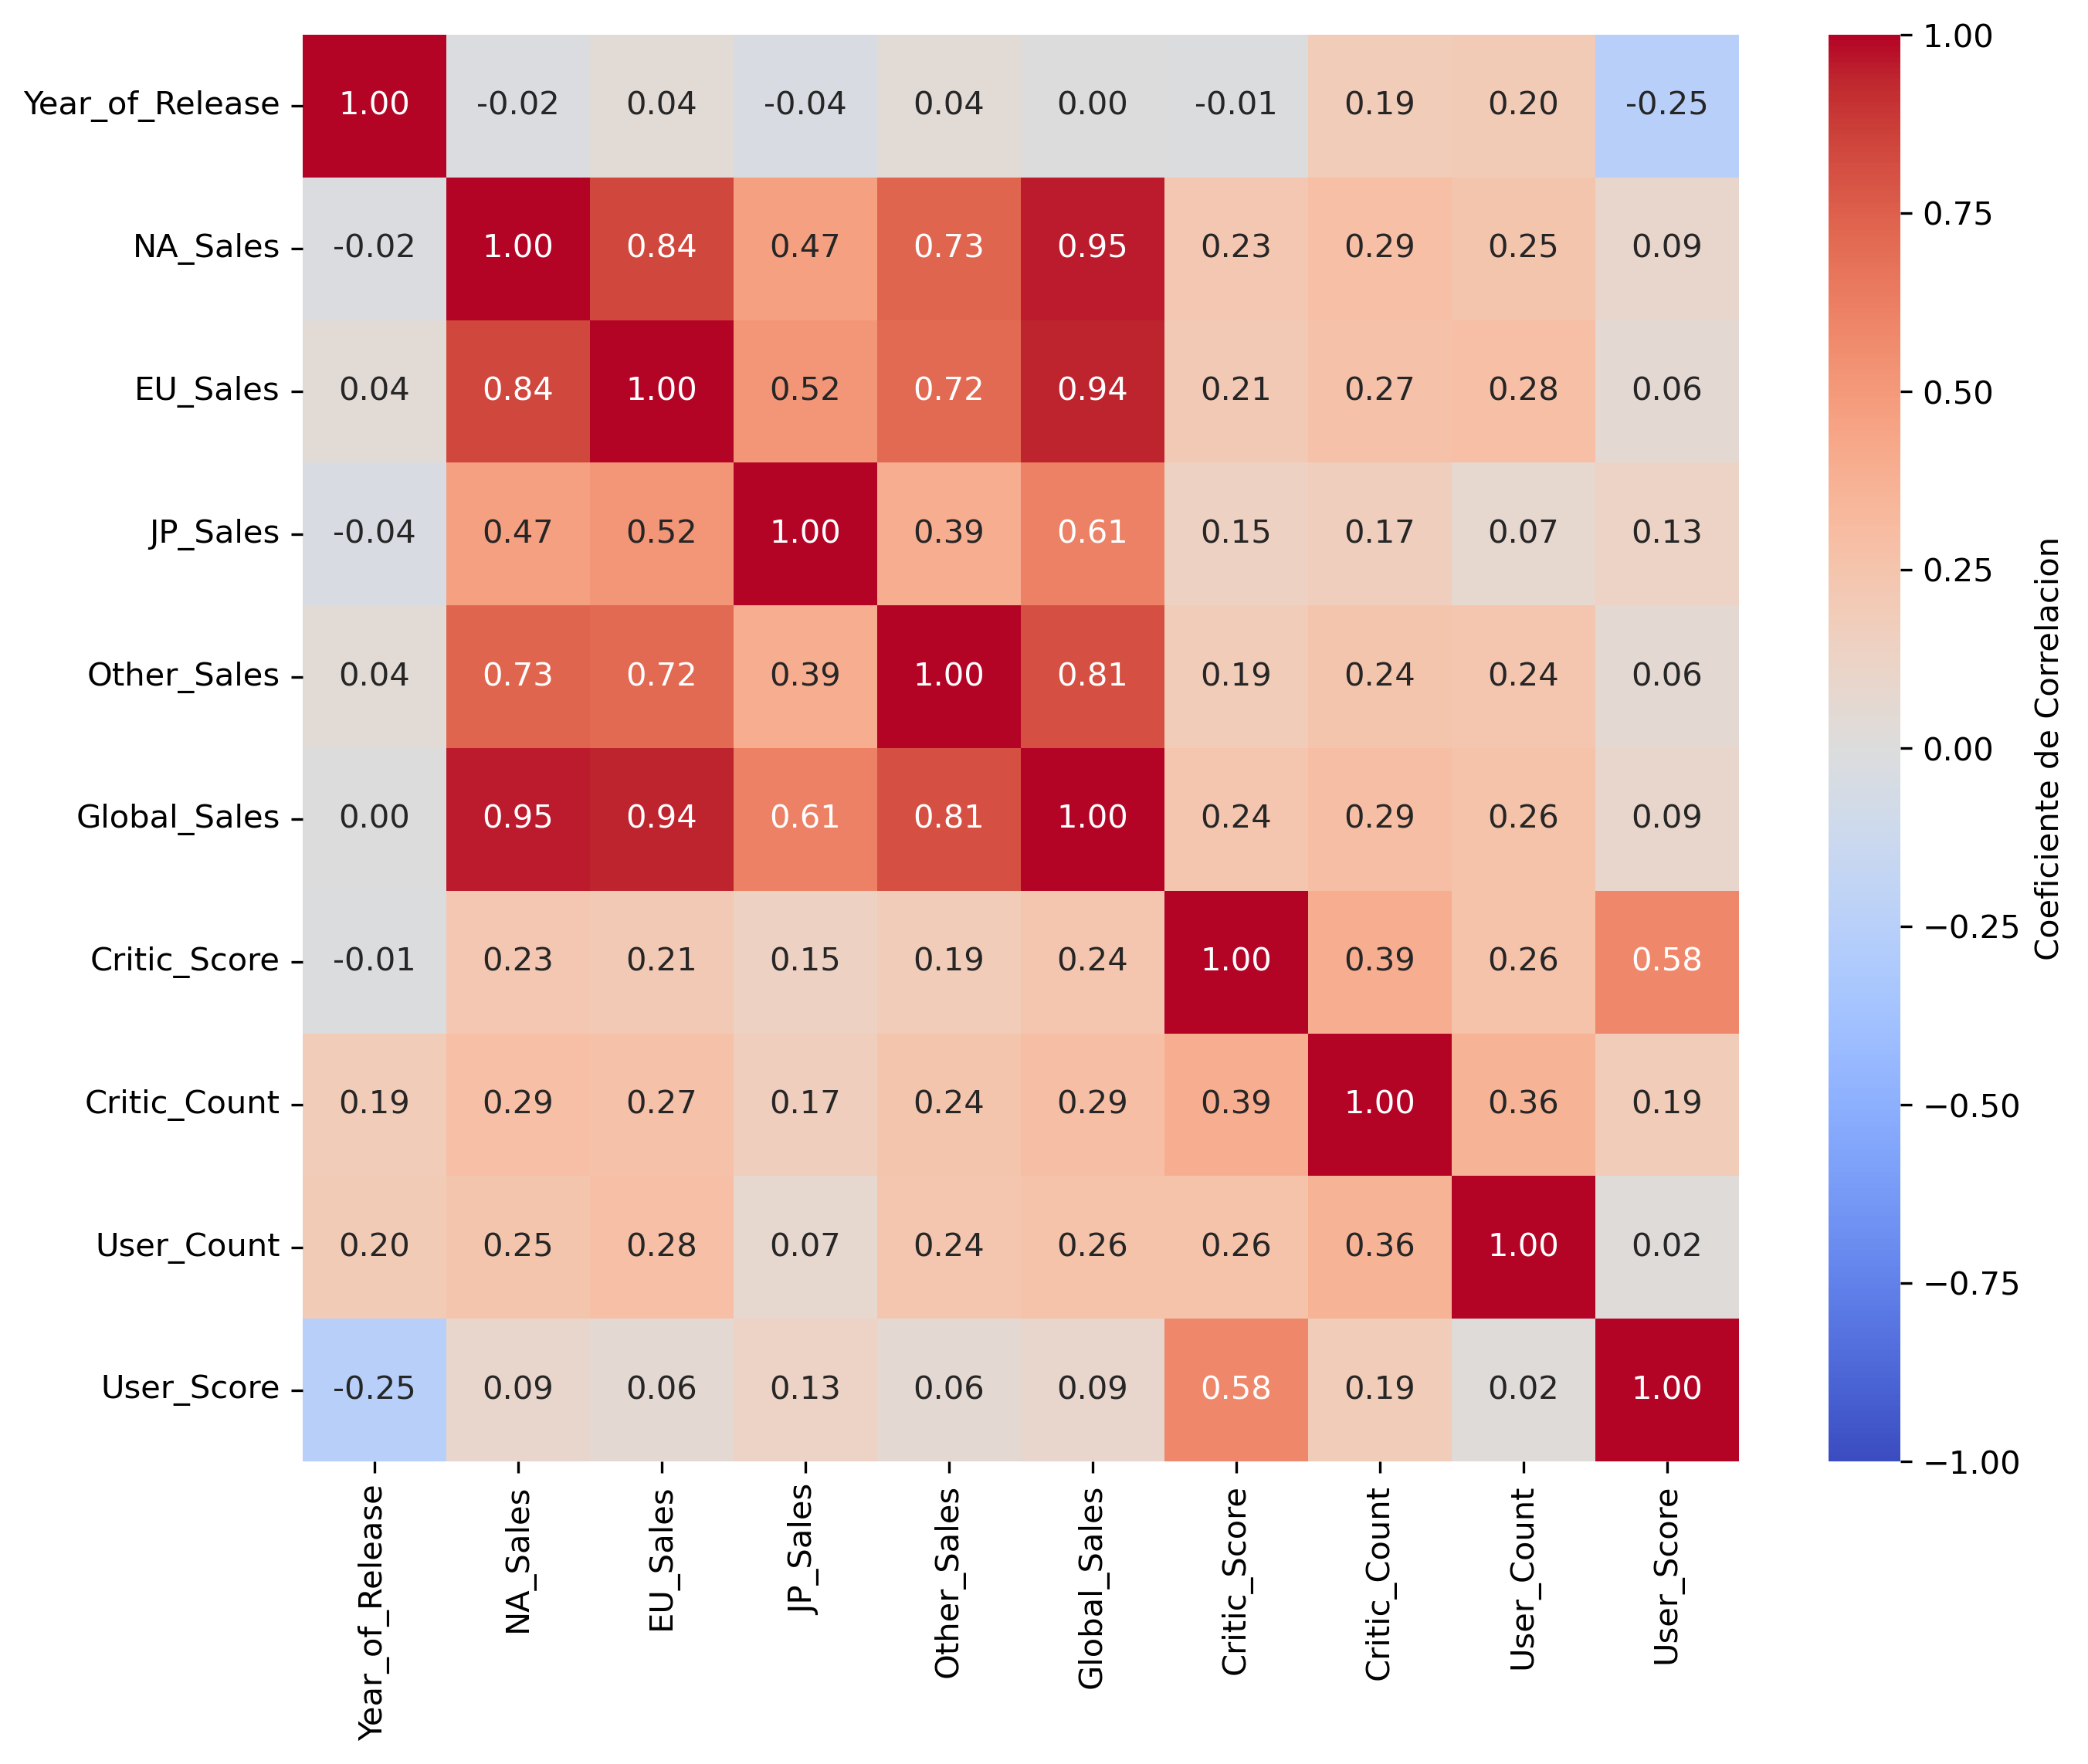

In [35]:
numeric = ['Year_of_Release', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales',
           'Critic_Score', 'Critic_Count', 'User_Count', 'User_Score']

data_num = data[numeric].dropna()
corr_num = data_num.corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
sns.heatmap(corr_num, annot=True, fmt='.2f', cmap='coolwarm',
            cbar_kws={'label': 'Coeficiente de Correlacion'}, ax=ax, vmin=-1, vmax=1)


Así, podemos ver cuales son los datos que se encuentran relacionados.

## 2. 

Analice la variable `Global_Sales`. ¿Cómo se relaciona con esta variable con los puntajes entregados por la crítica (`Critic_Score`) y los usuarios (`User_Score`)?

Text(0.5, 1.0, 'User Score vs Global Sales')

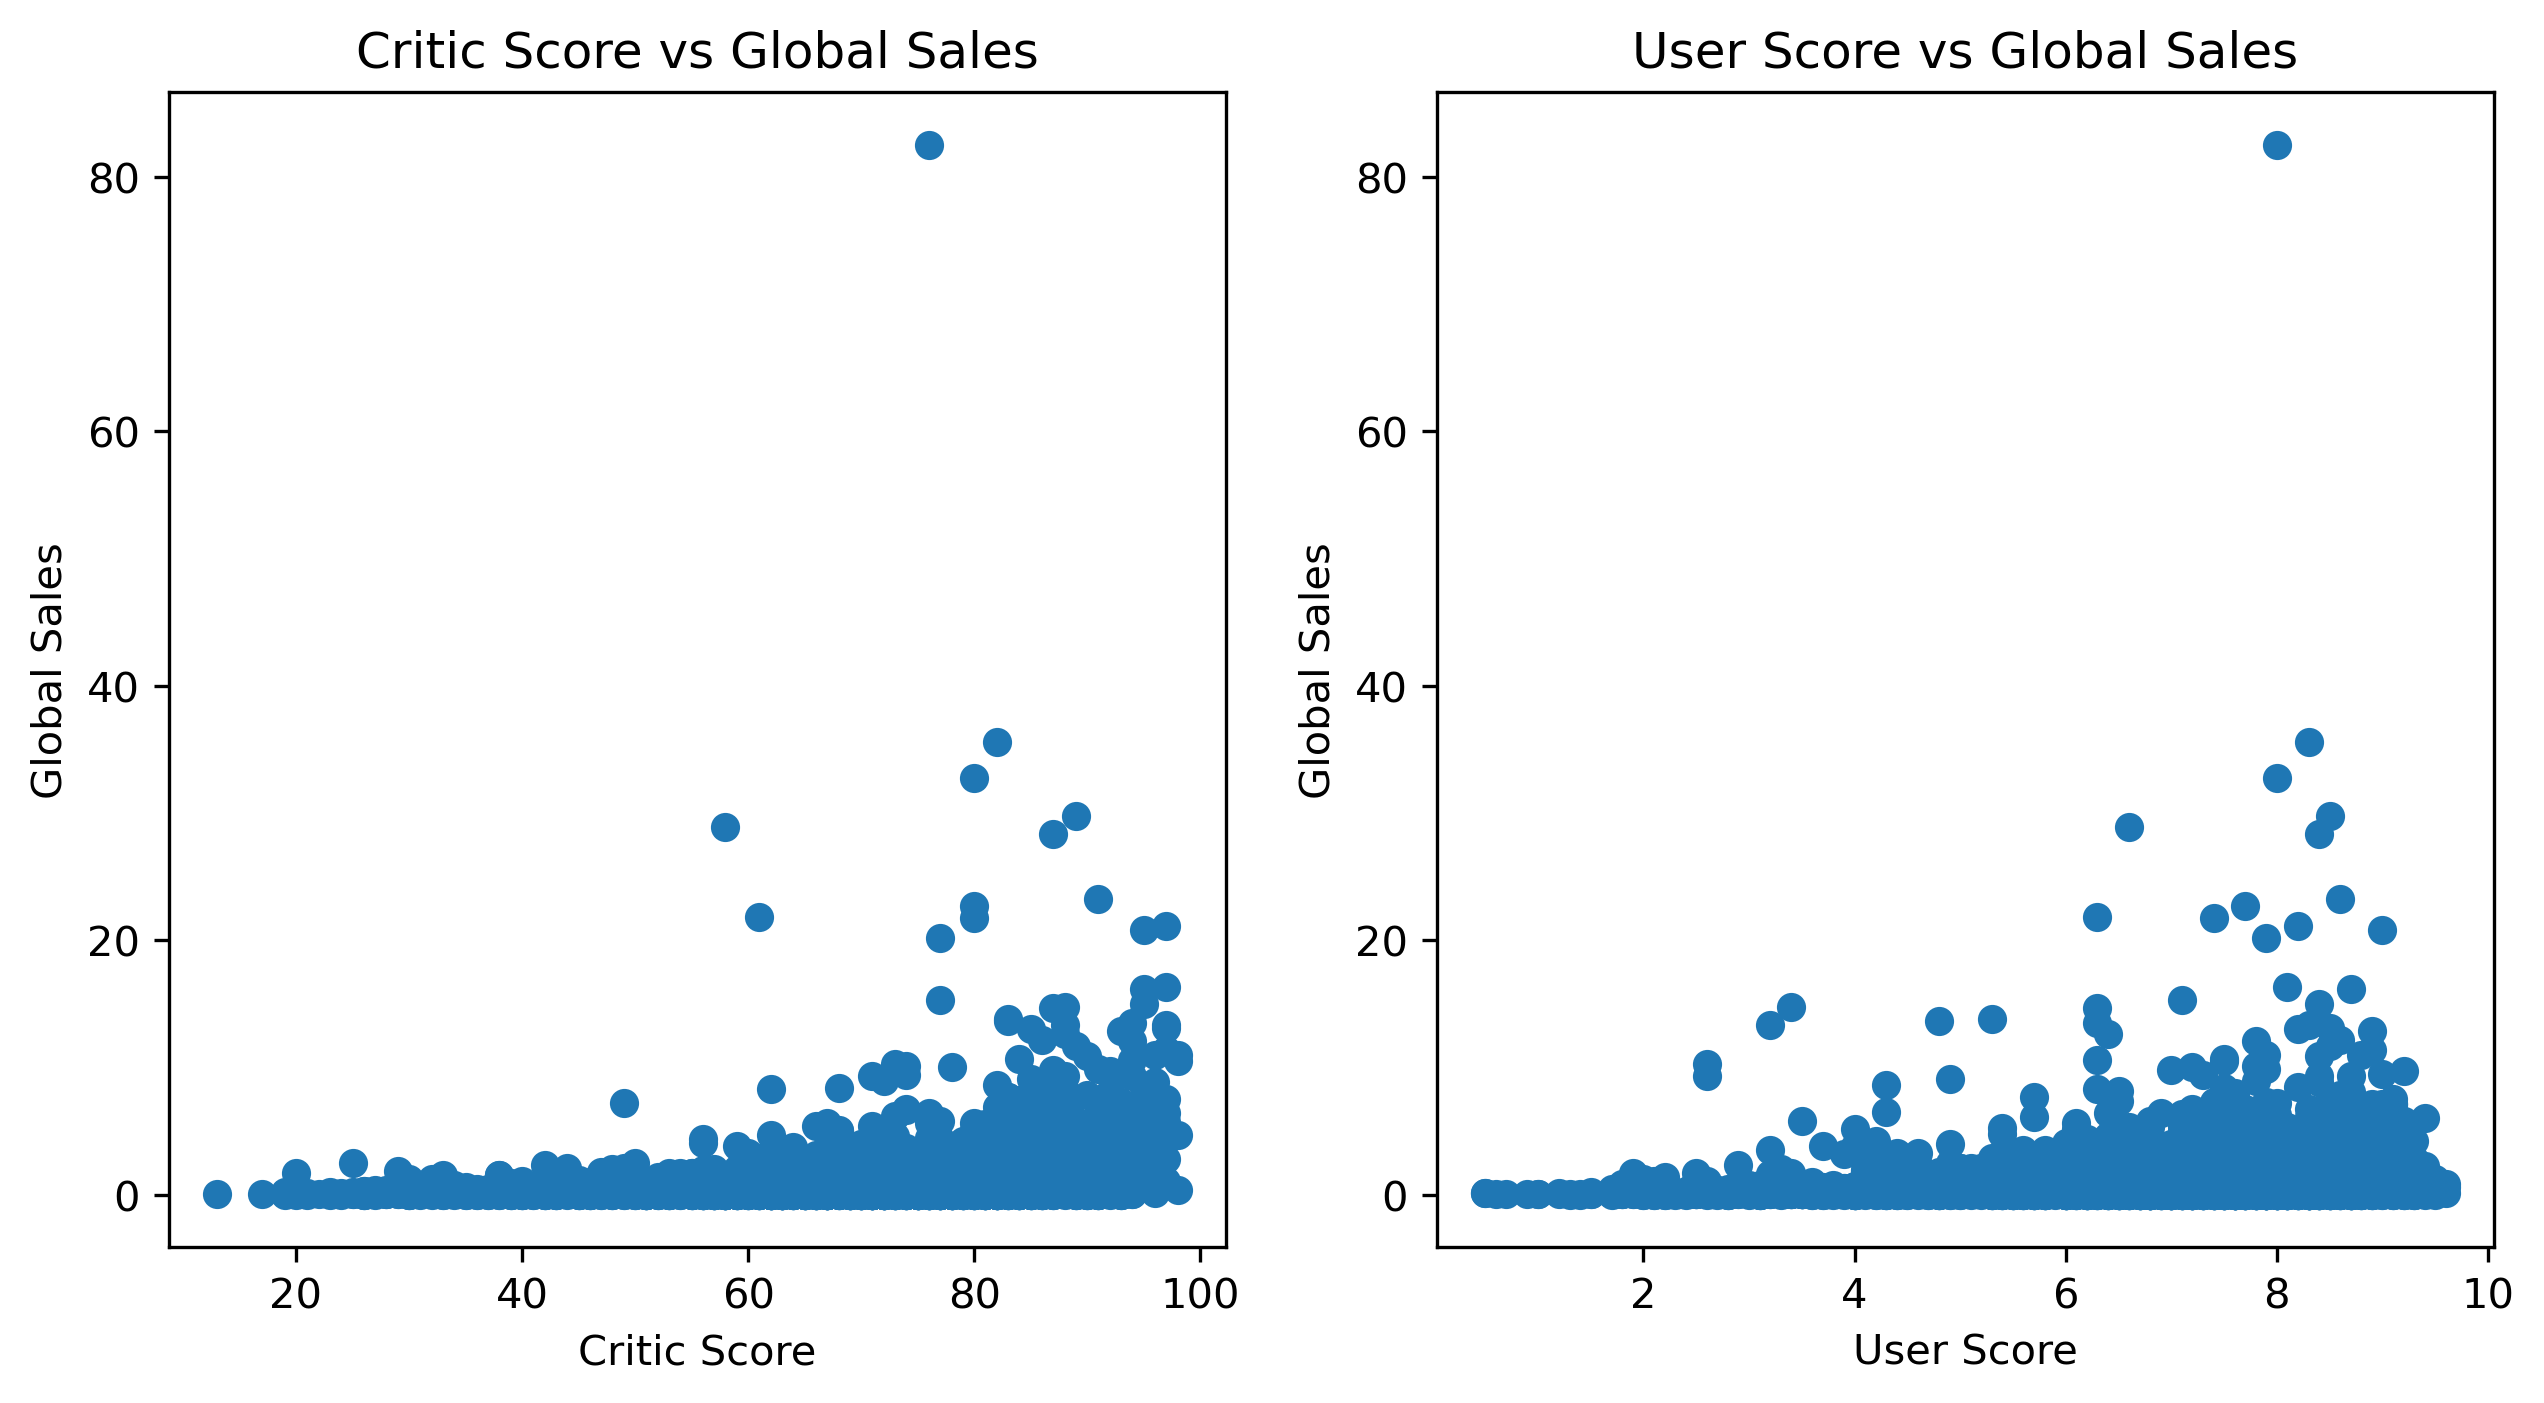

In [36]:
variables = data[['Global_Sales', 'Critic_Score', 'User_Score']].dropna()

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].scatter(variables['Critic_Score'], variables['Global_Sales'])
ax[0].set_xlabel('Critic Score')
ax[0].set_ylabel('Global Sales')
ax[0].set_title('Critic Score vs Global Sales')

ax[1].scatter(variables['User_Score'], variables['Global_Sales'])
ax[1].set_xlabel('User Score')
ax[1].set_ylabel('Global Sales')
ax[1].set_title('User Score vs Global Sales')


## 3.

Calcule la correlación de Pearson entre las variables explicativas `Critic_Score` y `User_Score` y la variable de respuesta `Global_Sales`. Reporte la varianza de cada variable, y la covarianza y correlación entre las variables explicativas y de respuesta.

Recordemos que:

La covarianza para dos variables aleatorias independientes X e Y se define como
$$
Cov(X, Y) = \sigma_{XY} = \mathbb{E}[(X - \mathbb{E}[X])(Y - \mathbb{E}[Y])] 
$$
$$
Cov_{XY,sample} = \frac{1}{n-1} \sum_{i = 1}^n (x_i - \overline{x})(y_i - \overline{y}) 
$$

Así, podemos definir la correlación de Pearson como:

$$
\rho_{XY} = \frac{\sigma_{XY}}{\sigma_X \sigma_Y}
$$
$$
\rho_{XY} = \frac{Cov(X, Y)}{\sqrt{\mathbb{Var}(X) \mathbb{Var}(Y)}} 
$$
$$
R_{XY} = \frac{ \sum_{i = 1}^n (x_i - \overline{x})(y_i - \overline{y})}{n-1} \frac{\sqrt{n-1}}{\sqrt{\sum_{i=1}^n (x_i -\overline{x})^2}} \frac{\sqrt{n-1}}{\sqrt{\sum_{i=1}^n (y_i -\overline{y})^2}} 
$$
$$
R_{XY}= \frac{ \sum_{i = 1}^n (x_i - \overline{x})(y_i - \overline{y})}{ \sqrt{\sum_{i=1}^n (x_i -\overline{x})^2} \sqrt{\sum_{i=1}^n (y_i -\overline{y})^2}}
$$

In [37]:
# Varianzas muestrales (ddof=1)
critic_var = np.var(variables["Critic_Score"], ddof=1)
user_var   = np.var(variables["User_Score"],   ddof=1)
global_var = np.var(variables["Global_Sales"], ddof=1)

# np.cov retorna matriz 2x2 -> [0][1] es la covarianza
covar_critic_global = np.cov(variables["Critic_Score"], variables["Global_Sales"])[0][1]
covar_user_global   = np.cov(variables["User_Score"],   variables["Global_Sales"])[0][1]

corr_critic_global = covar_critic_global / (np.sqrt(critic_var) * np.sqrt(global_var))
corr_user_global   = covar_user_global   / (np.sqrt(user_var)   * np.sqrt(global_var))

print(f"Varianza Critic Score:  {critic_var:.4f}")
print(f"Varianza User Score:    {user_var:.4f}")
print(f"Varianza Global Sales:  {global_var:.4f}")
print(f"Cov(Critic, Sales):     {covar_critic_global:.4f}")
print(f"Cov(User, Sales):       {covar_user_global:.4f}")
print(f"R(Critic, Sales):       {corr_critic_global:.4f}")
print(f"R(User, Sales):         {corr_user_global:.4f}")


Varianza Critic Score: 192.7809
Varianza User Score: 2.0862
Varianza Global Sales: 3.7146
Covarianza Critic Score - Global Sales: 6.3369
Covarianza User Score - Global Sales: 0.2456
Correlacion Critic Score - Global Sales: 0.2368
Correlacion User Score - Global Sales: 0.0882


## 4. 

Realice ahora un test de hipótesis sobre el coeficiente de correlación. ¿Qué tan significativos son los resultados previamente calculados?


El coeficiente de correlación de Pearson puede ser utilizado como un test de hipótesis también. En este caso se posee el siguiente de hipotesis nula y alternativa:
$$
H_0: \rho = 0
$$
$$
H_a: \rho\neq 0
$$

En este caso, el estadístico de prueba que se utiliza es:
$$
T_0 = \frac{R \sqrt{n-2}}{\sqrt{1-R^2}}
$$

Donde $R = R_{xy}$ que es el coeficiente de correlación de Pearson. El estadístico $T_0$ sigue una distribución T con $n-2$ grados de libertad, i.e., $T_0\sim t_{n-2}$. Así, podemos evaluar si la correlación encontrada es significativa al existir algún tipo de correlación, y por ende, relación lineal. 


In [38]:
import scipy.stats as st

# H0: rho = 0  ->  p < 0.05 indica correlacion significativa
corr_critic_global, p_value_critic = st.pearsonr(variables["Critic_Score"], variables["Global_Sales"])
corr_user_global,   p_value_user   = st.pearsonr(variables["User_Score"],   variables["Global_Sales"])

pd.DataFrame({
    "Variable 1":  ["Critic Score", "User Score"],
    "Variable 2":  ["Global Sales", "Global Sales"],
    "Correlacion": [corr_critic_global, corr_user_global],
    "p-value":     [p_value_critic, p_value_user],
})


,Variable 1,Variable 2,Correlacion,p-value
0,Critic Score,Global Sales,0.236805,3.222004e-92
1,User Score,Global Sales,0.088211,6.700688e-14


Al igual que los test paramétricos, que preveían alternativas a los métodos t-test o ANOVA, existen alternativas para la correlación de Pearson. 

En este caso, tenemos la correlación de Spearman ([spearmanr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)), la cual permite evaluar la correlación entre dos sets de datos mediante la utilización de los rankings de los datos.

In [39]:
# Spearman: alternativa no parametrica, mas robusta frente a outliers
corr_critic_global, p_value_critic = st.spearmanr(variables["Critic_Score"], variables["Global_Sales"])
corr_user_global,   p_value_user   = st.spearmanr(variables["User_Score"],   variables["Global_Sales"])

pd.DataFrame({
    "Variable 1":  ["Critic Score", "User Score"],
    "Variable 2":  ["Global Sales", "Global Sales"],
    "Correlacion": [corr_critic_global, corr_user_global],
    "p-value":     [p_value_critic, p_value_user],
})


,Variable 1,Variable 2,Correlacion,p-value
0,Critic Score,Global Sales,0.375849,4.563159e-240
1,User Score,Global Sales,0.157774,2.643829e-41


Existen otros tipos de metricas similares a la correlación. Por ejemplo:
- Medida de información mutua: [Mutual Information](https://www.kaggle.com/code/ryanholbrook/mutual-information). Para relaciones no-lineales
- Kendall Tau: [Kendall Tau](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html). Pero este se usa para datos ordinales.

Cada uno con diferentes fortalezas y debilidades en su formulación.

## 5.

Realice una **regresión lineal simple** que relacione las variables analizadas. 

### a.
Calcule los parámetros de la regresión con las formulas correspondientes.

La ecuación de la regresión lineal simple es:
$$
y_i = \beta_1 x_i + \beta_0 + \varepsilon
$$

Una buena forma para poder realizar la estimación de parámetros es minimizar la suma de del error cuadrático:
$$
\min L = \sum_{i = 1}^n (y_i - \beta_1 x_i - \beta_0 )^2\\
$$
Donde $L$ puede verse como:

$$
L = \sum_{i = 1}^n (y_i - \beta_1 x_i - \beta_0 )^2 = \varepsilon_i ^2
$$

En este caso, tenemos un problema de optimización que se puede resolver al obtener un gradiente igual a 0. De esta forma:
$$
\nabla_{\beta_0, \beta_1} L(\widehat{\beta}_0, \widehat{\beta}_1) = \mathbf{0}
$$
En donde buscamos los estimadores para $\beta_0$ y $\beta_1$, $\widehat{\beta}_0$ y $\widehat{\beta}_1$ respectivamente. Así, tenemos el siguiente sistema de ecuaciones

$$
\frac{\partial L}{\partial \beta_0}\left\vert_{\widehat{\beta}_0, \widehat{\beta}_1}\right. = -2\sum_{i=1}^n (y_i -\widehat{\beta}_0 - \widehat{\beta}_1x_i) = 0 
$$

$$
\frac{\partial L}{\partial \beta_1}\left\vert_{\widehat{\beta}_0, \widehat{\beta}_1}\right. = -2\sum_{i=1}^n (y_i -\widehat{\beta}_0 - \widehat{\beta}_1x_i)x_i = 0
$$

Trabajando estas ecuaciones llegamos a las **ecuaciones cuadráticas normales.** (least squares normal equations).

$$

\widehat{\beta_1} = \frac{S_{XY}}{S_{XX}}
$$
$$
\widehat{\beta_0} = \overline{y} - \widehat{\beta_1}\overline{x}
$$

Donde
$$
S_{XY} = \sum_{i=1}^n (y_i - \overline{y}) (x_i -\overline{x}) 
$$
$$
S_{XX} = \sum_{i = 1}^n (x_i - \overline{x})^2
$$

Es interesante ver como el coeficiente $\widehat{\beta}_1$ se relaciona con la correlacion de Pearson.

Recordando que $R_{XY} = \dfrac{S_{XY}}{\sqrt{S_{XX} \cdot SS_T}}$ y que $\widehat{\beta}_1 = \dfrac{S_{XY}}{S_{XX}}$, podemos despejar y mostrar que:

$$
\widehat{\beta}_1 = R_{XY} \cdot \sqrt{\frac{SS_T}{S_{XX}}}
$$

Esto implica que **$\widehat{\beta}_1$ y $R_{XY}$ siempre tienen el mismo signo**: si la correlacion es positiva, la pendiente de la recta de regresion tambien lo es, y viceversa.


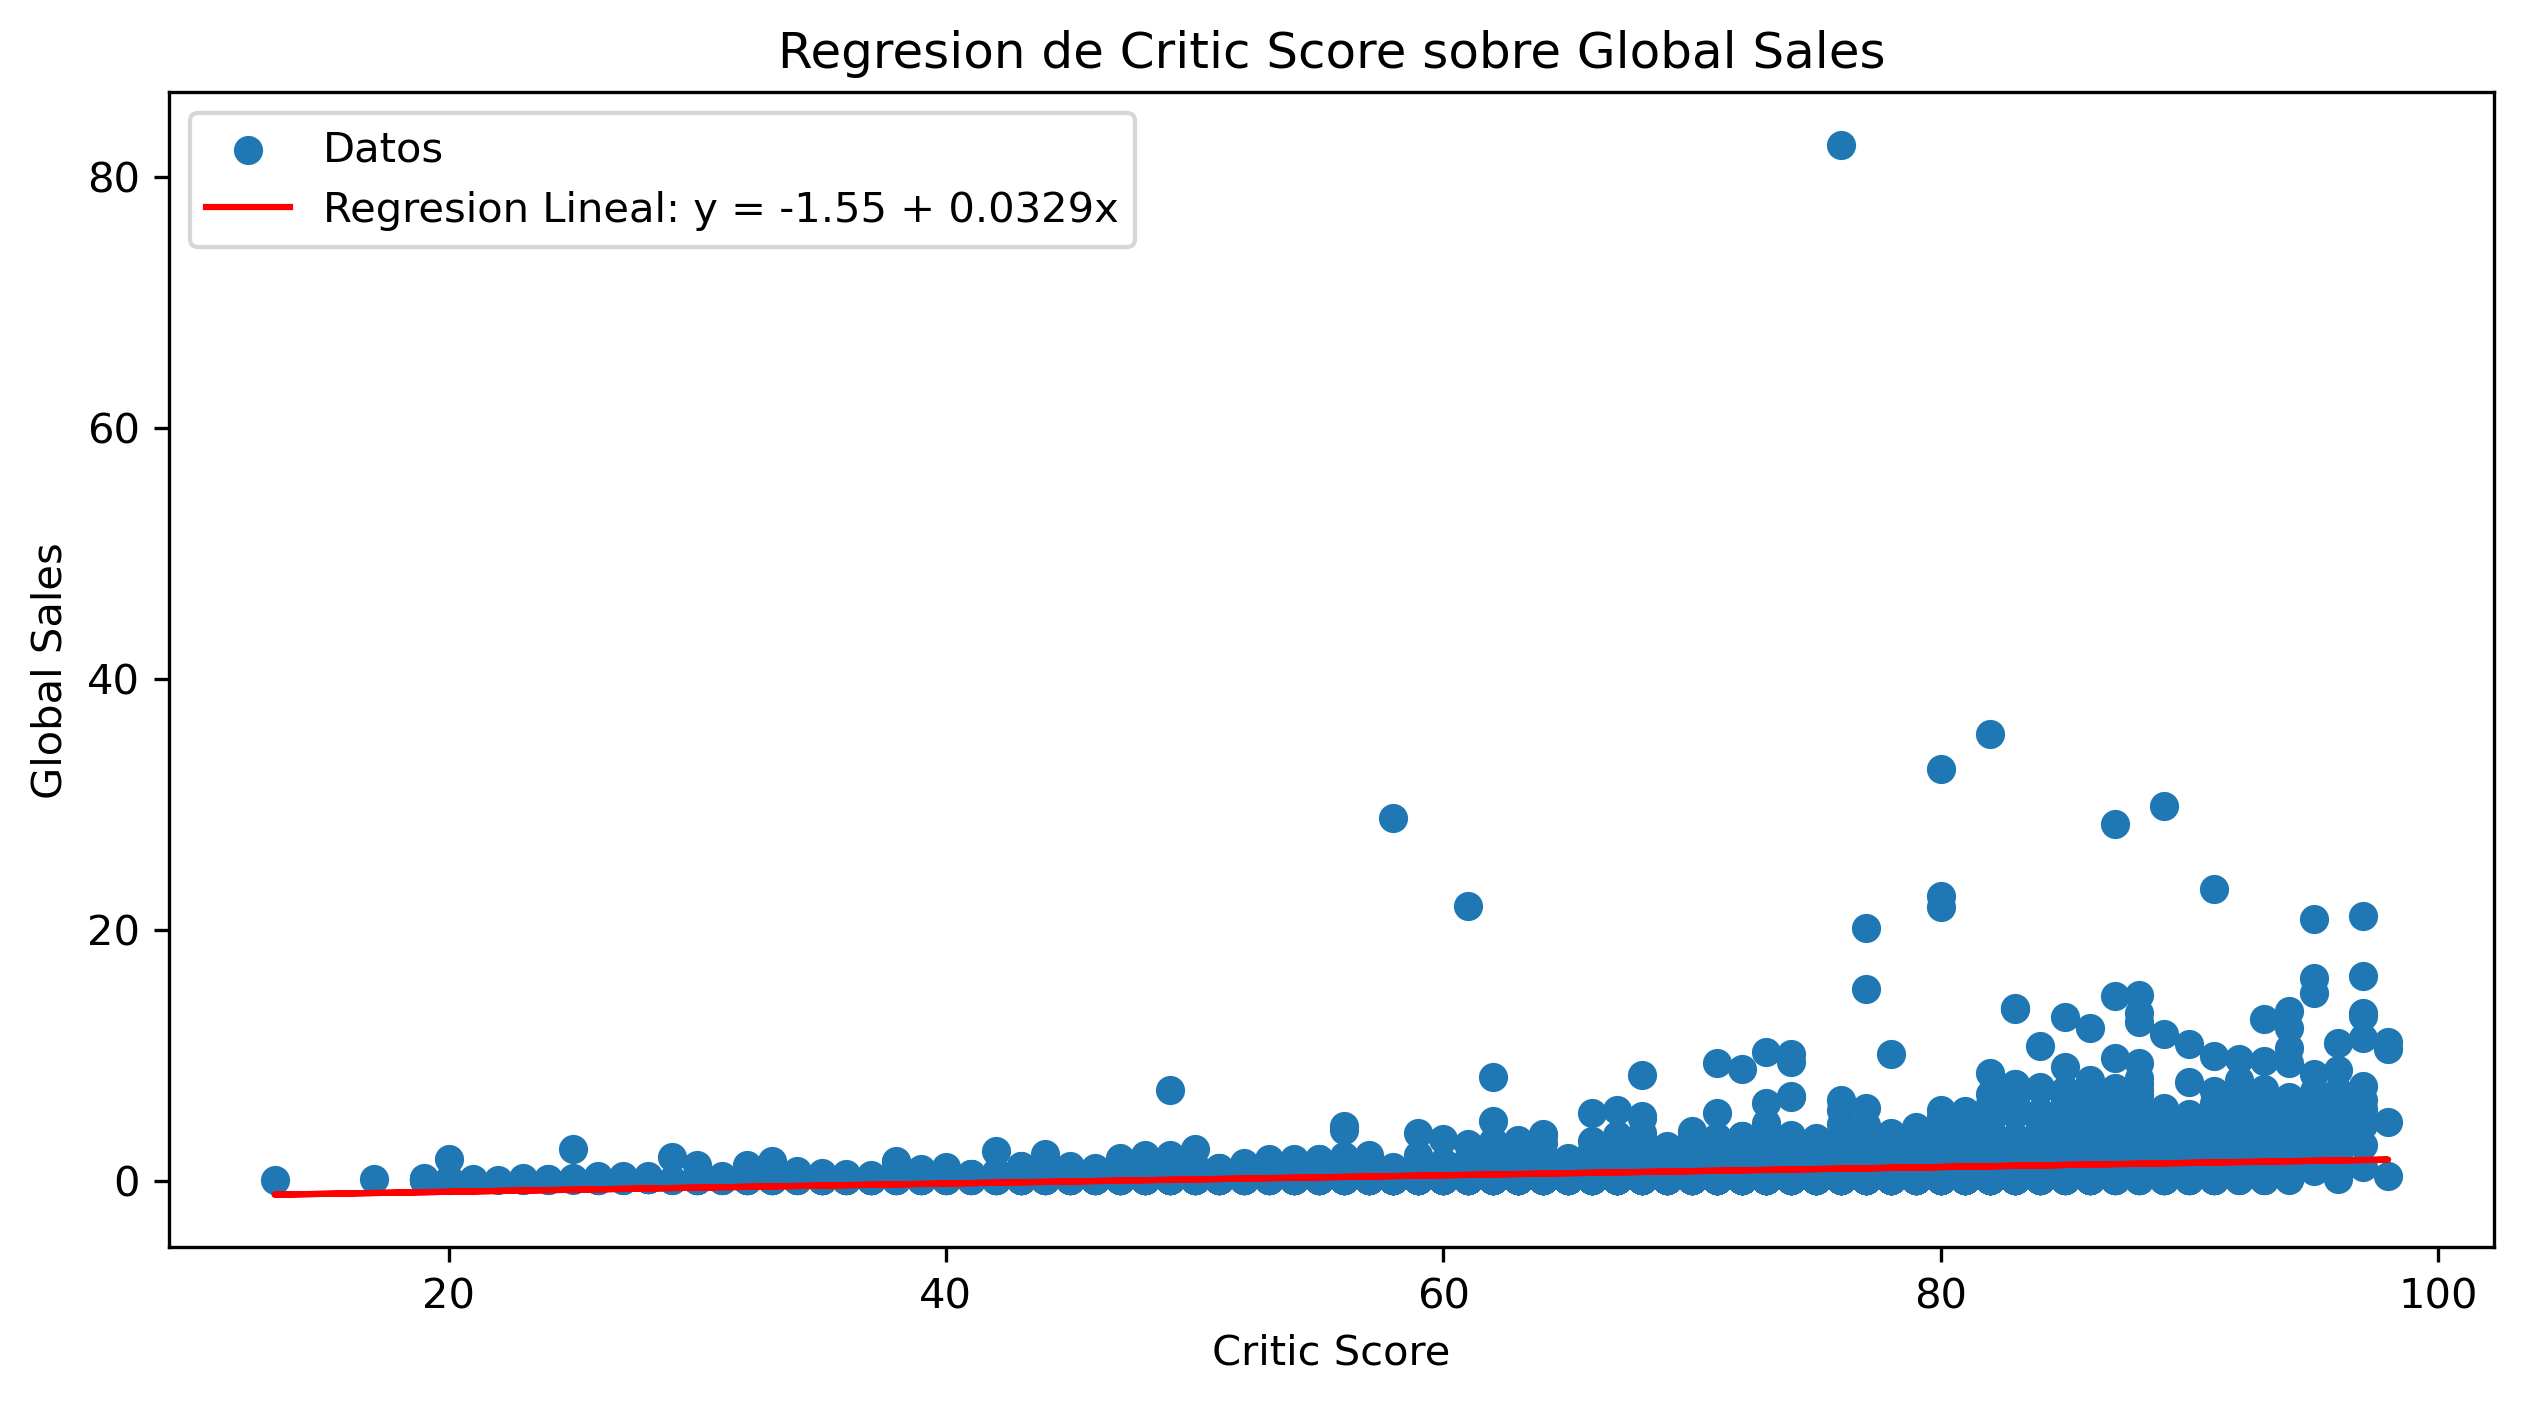

In [40]:
media_critic = variables["Critic_Score"].mean()
media_user   = variables["User_Score"].mean()
media_sales  = variables["Global_Sales"].mean()

# --- Critic_Score -> Global_Sales ---
s_XY = np.sum((variables["Critic_Score"] - media_critic) * (variables["Global_Sales"] - media_sales))
s_XX = np.sum((variables["Critic_Score"] - media_critic) ** 2)

b1_critic = s_XY / s_XX
b0_critic = media_sales - b1_critic * media_critic

y_hat = b0_critic + b1_critic * variables["Critic_Score"]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables["Critic_Score"], variables["Global_Sales"], label="Datos")
ax.plot(variables["Critic_Score"], y_hat, color="red",
        label=f"y = {b0_critic:.2f} + {b1_critic:.4f}x")
ax.set_xlabel("Critic Score")
ax.set_ylabel("Global Sales")
ax.set_title("Regresion: Critic Score -> Global Sales")
ax.legend()


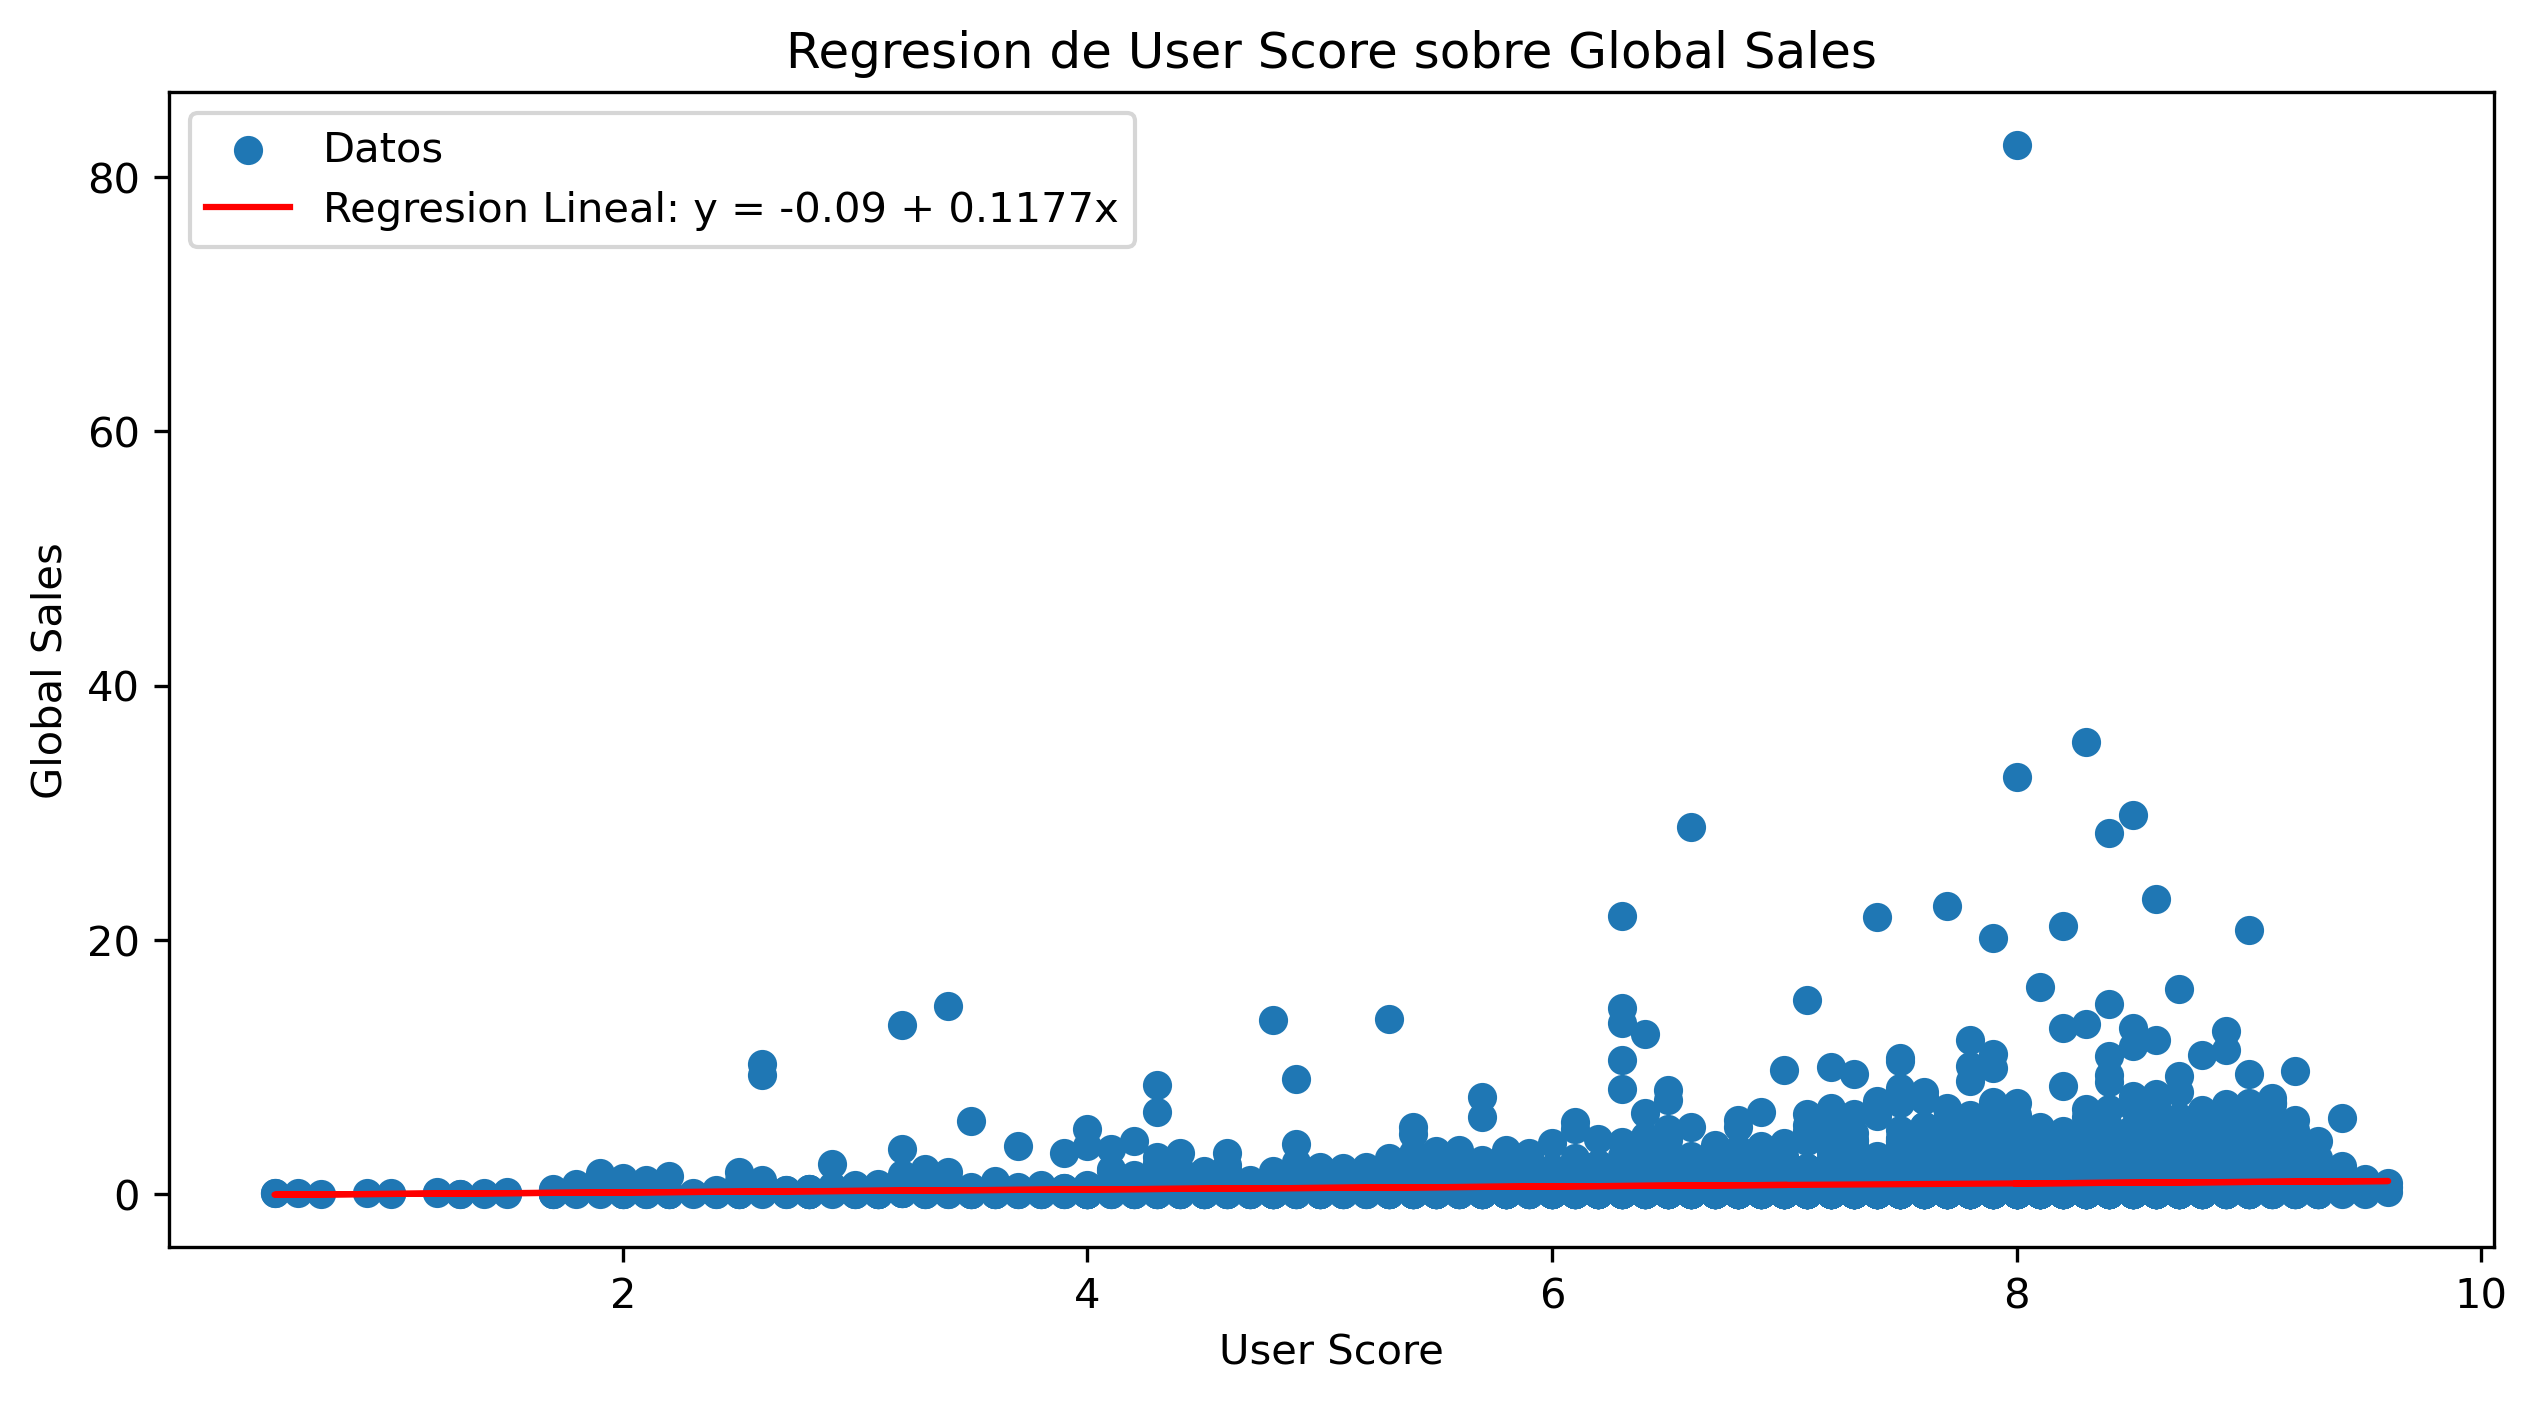

In [41]:
# --- User_Score -> Global_Sales ---
s_XY = np.sum((variables['User_Score'] - media_user) * (variables['Global_Sales'] - media_sales))
s_XX = np.sum((variables['User_Score'] - media_user) ** 2)

b1_user = s_XY / s_XX
b0_user = media_sales - b1_user * media_user

y_hat = b0_user + b1_user * variables['User_Score']

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['User_Score'], variables['Global_Sales'], label='Datos')
ax.plot(variables['User_Score'], y_hat, color='red',
        label=f'y = {b0_user:.2f} + {b1_user:.4f}x')
ax.set_xlabel('User Score')
ax.set_ylabel('Global Sales')
ax.set_title('Regresion: User Score -> Global Sales')
ax.legend()


### b.

Utilice la función de su librería favorita en `python` y compare con los resultados anteriores.

                            OLS Regression Results                            
Dep. Variable:           Global_Sales   R-squared:                       0.056
Model:                            OLS   Adj. R-squared:                  0.056
Method:                 Least Squares   F-statistic:                     427.1
Date:                Mon, 20 Apr 2026   Prob (F-statistic):           3.22e-92
Time:                        00:27:18   Log-Likelihood:                -14714.
No. Observations:                7191   AIC:                         2.943e+04
Df Residuals:                    7189   BIC:                         2.945e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -1.5495      0.114    -13.610   

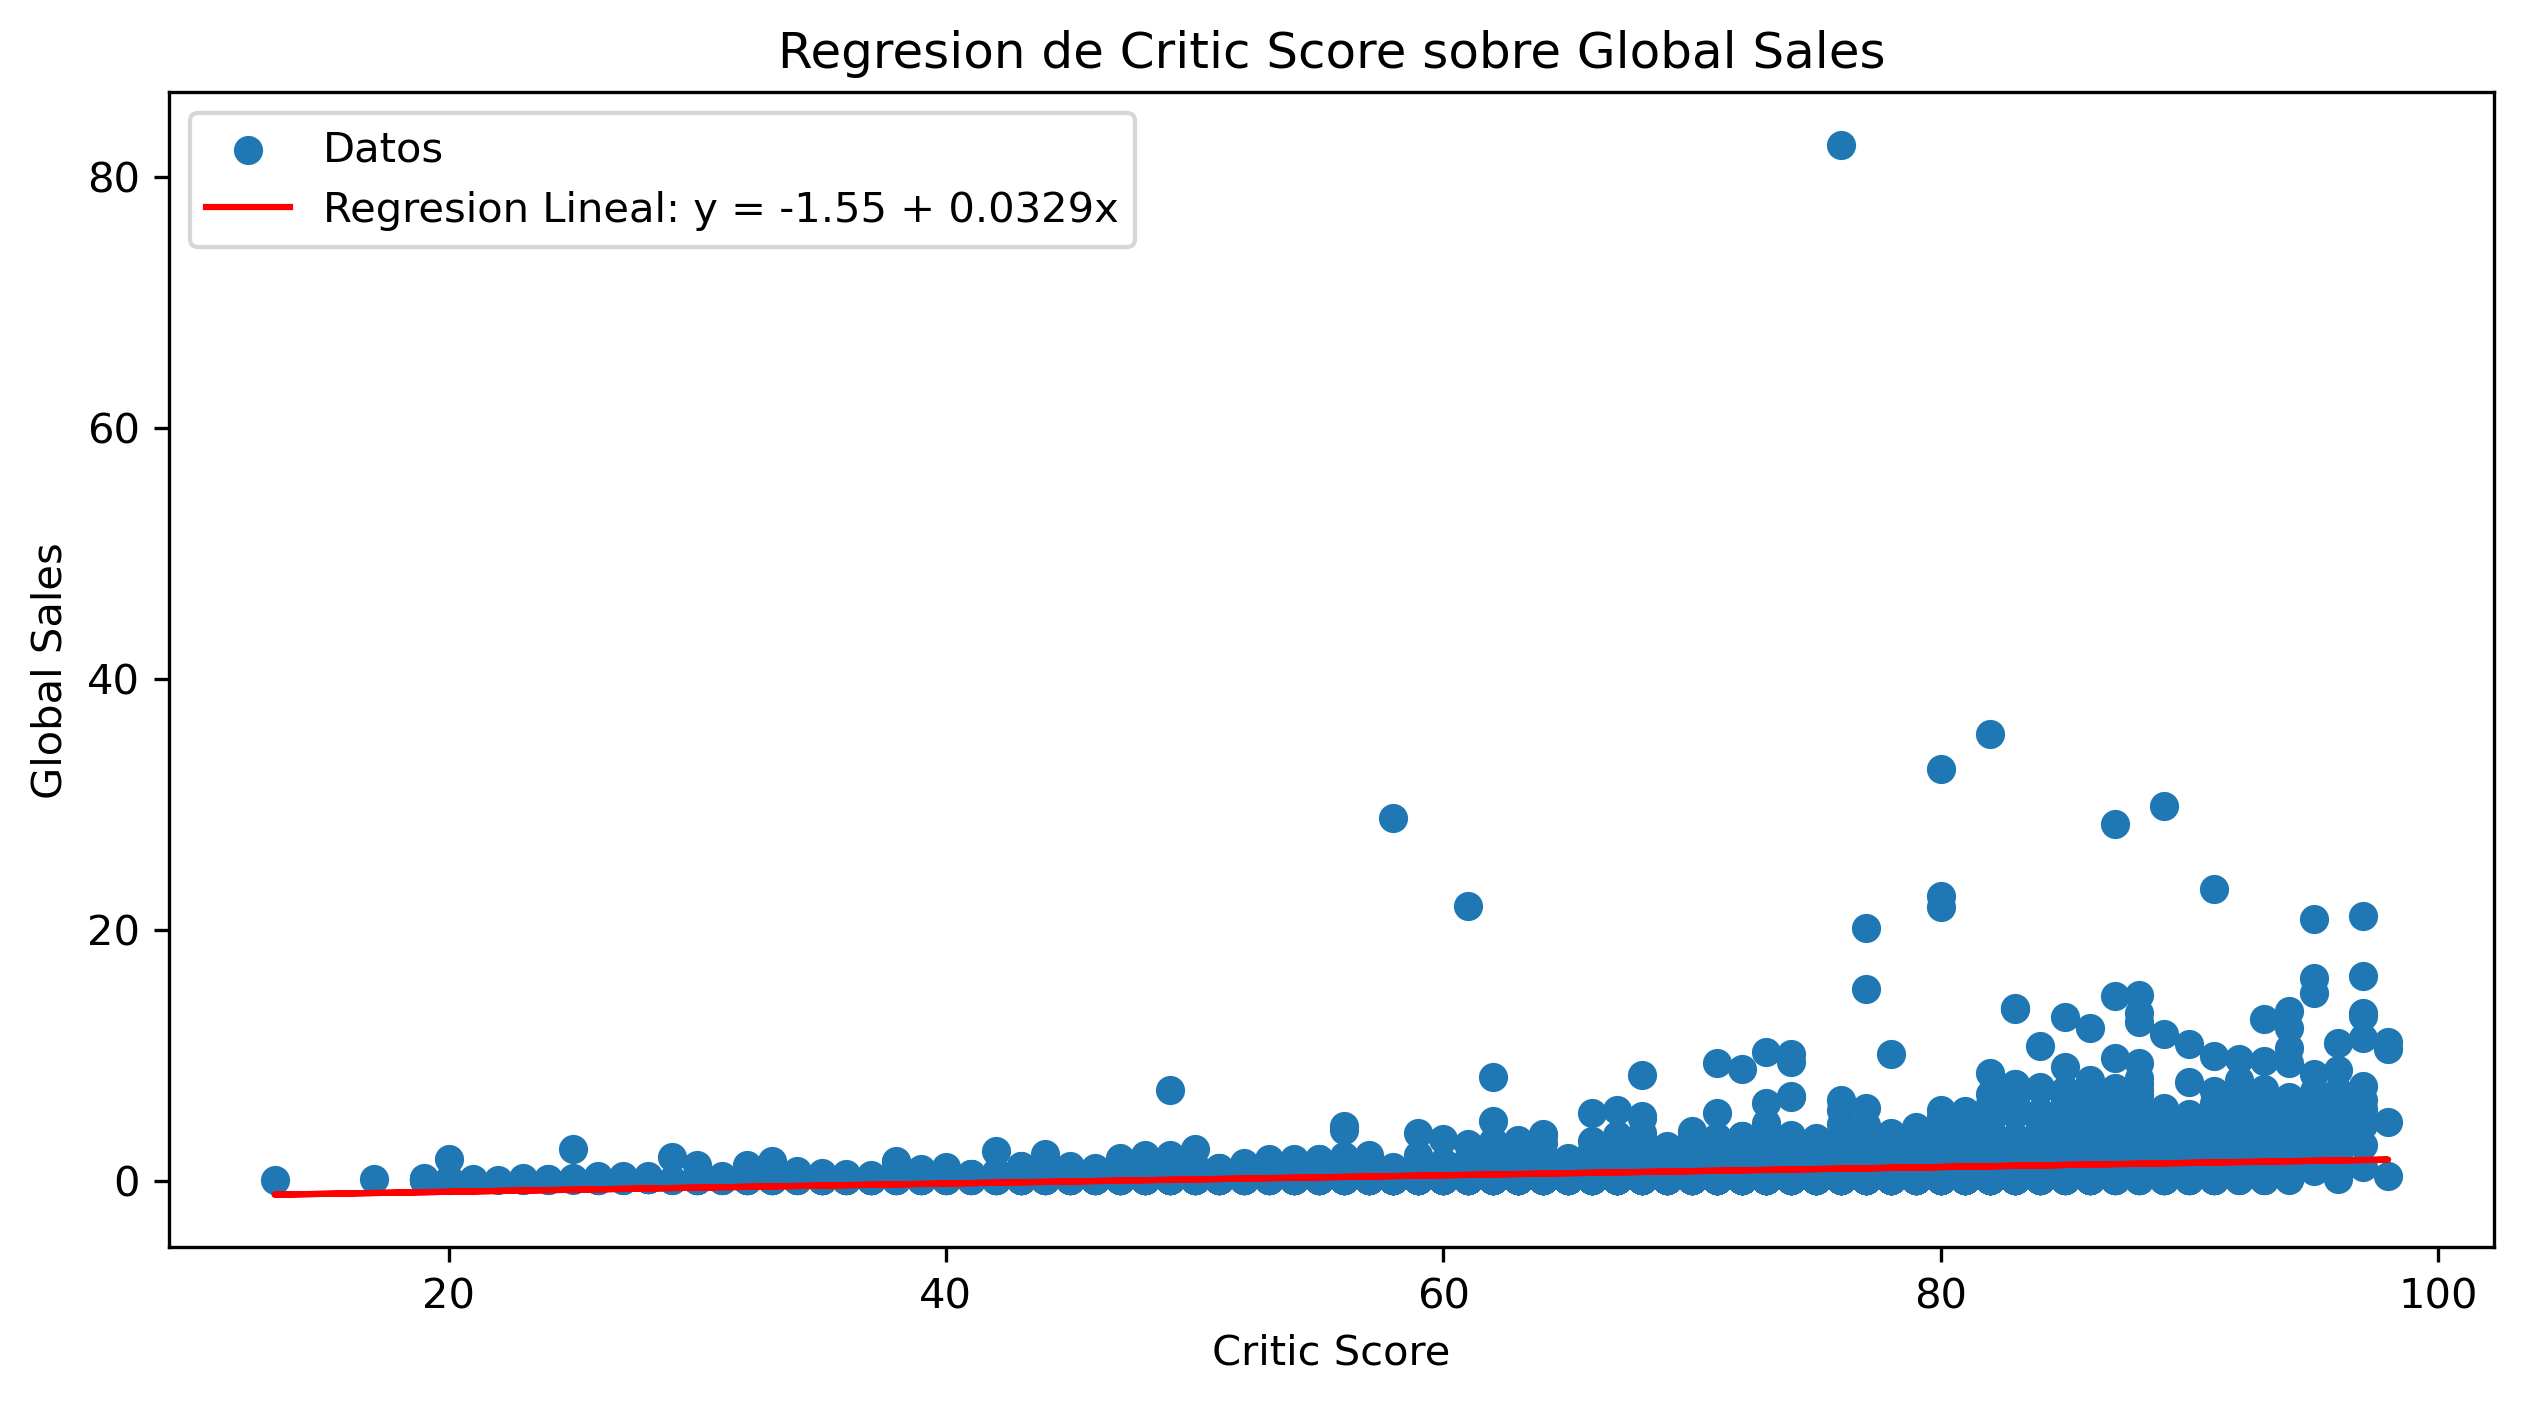

In [42]:
import statsmodels.api as sm

y = variables['Global_Sales']
x = sm.add_constant(variables[['Critic_Score']])
model = sm.OLS(y, x).fit()
print(model.summary())

beta_0, beta_1 = model.params
y_hat = beta_0 + beta_1 * variables['Critic_Score']

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['Critic_Score'], variables['Global_Sales'], label='Datos')
ax.plot(variables['Critic_Score'], y_hat, color='red',
        label=f'y = {beta_0:.2f} + {beta_1:.4f}x')
ax.set_xlabel('Critic Score')
ax.set_ylabel('Global Sales')
ax.set_title('OLS: Critic Score -> Global Sales')
ax.legend()


                            OLS Regression Results                            
Dep. Variable:           Global_Sales   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     56.38
Date:                Mon, 20 Apr 2026   Prob (F-statistic):           6.70e-14
Time:                        00:27:18   Log-Likelihood:                -14893.
No. Observations:                7191   AIC:                         2.979e+04
Df Residuals:                    7189   BIC:                         2.980e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0859      0.115     -0.749      0.4

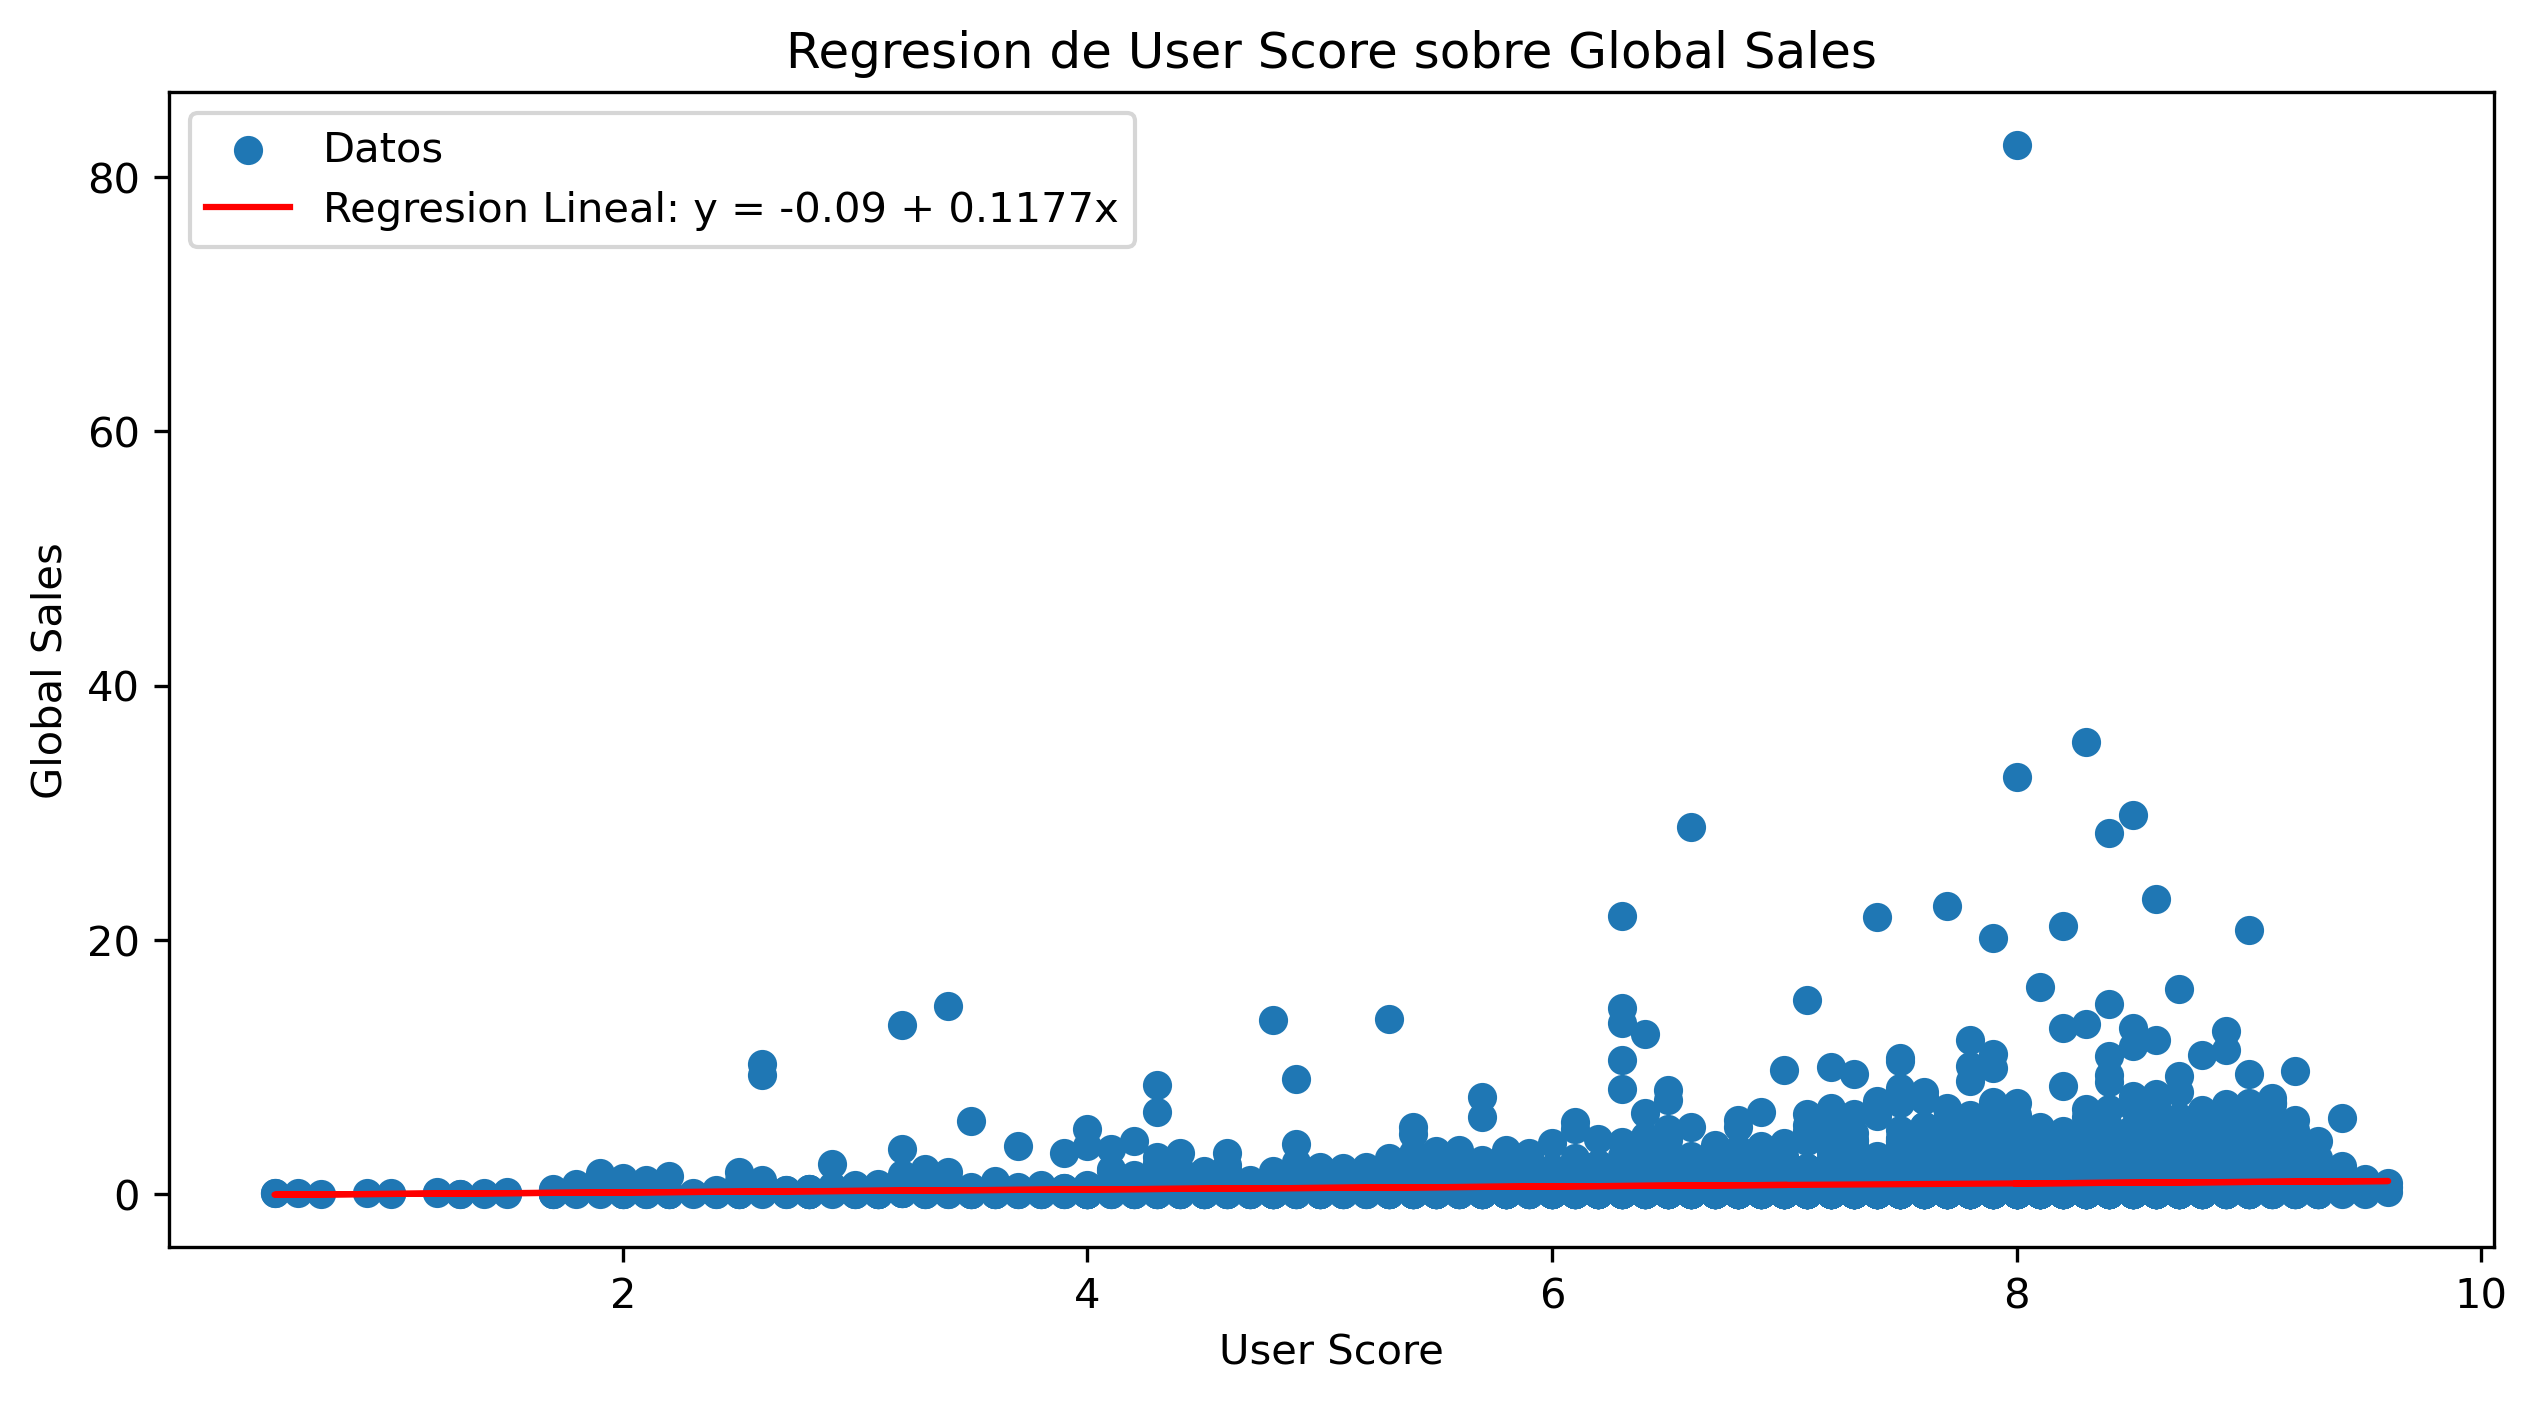

In [43]:
y = variables['Global_Sales']
x = sm.add_constant(variables[['User_Score']])
model = sm.OLS(y, x).fit()
print(model.summary())

beta_0, beta_1 = model.params
y_hat = beta_0 + beta_1 * variables['User_Score']

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['User_Score'], variables['Global_Sales'], label='Datos')
ax.plot(variables['User_Score'], y_hat, color='red',
        label=f'y = {beta_0:.2f} + {beta_1:.4f}x')
ax.set_xlabel('User Score')
ax.set_ylabel('Global Sales')
ax.set_title('OLS: User Score -> Global Sales')
ax.legend()


### c. 
Realice el mismo procedimiento anterior, pero ahora para el coeficiente de determinación ($R^2$).

En este caso, hay que comparar el output de el coeficiente de determinación $R^2$ desde el cálculo manual y el cálculo con python.

Recordemos que el coeficiente de determinación está determinado por:
$$
R^2 = \frac{SS_R}{SS_T} = 1 - \frac{SS_E}{SS_T}
$$

Donde 
$$

SS_E = \sum_{i=1}^n(y_i - \widehat{y})^2 
$$
$$
SS_T = \sum_{i=1}^n (y_i - \overline{y})^2
$$
$$
SS_R = \widehat{\beta}_1 S_{XY}
$$

Notar que $SS_T = SS_R + SS_E$.

El coeficiente de determinación permite comprender cual es la cantidad de varianza de los datos que captura el modelo. Así, el modelo captura el $100 R^2\%$ de la varianza de los datos


In [44]:
# --- R^2: Critic_Score -> Global_Sales ---
y = variables['Global_Sales']
x = sm.add_constant(variables[['Critic_Score']])
model = sm.OLS(y, x).fit()
beta_0, beta_1 = model.params

SS_T = np.sum((y - y.mean()) ** 2)
SS_E = np.sum((y - (beta_0 + beta_1 * variables['Critic_Score'])) ** 2)
R2   = 1 - SS_E / SS_T

print(f'R2 calculado: {R2:.4f}')
print(f'R2 modelo:    {model.rsquared:.4f}')


Coeficiente de determinacion Calculado: 0.0561
Coeficiente de determinacion python:    0.0561


In [45]:
# --- R^2: User_Score -> Global_Sales ---
y = variables['Global_Sales']
x = sm.add_constant(variables[['User_Score']])
model = sm.OLS(y, x).fit()
beta_0, beta_1 = model.params

SS_T = np.sum((y - y.mean()) ** 2)
SS_E = np.sum((y - (beta_0 + beta_1 * variables['User_Score'])) ** 2)
R2   = 1 - SS_E / SS_T

print(f'R2 calculado: {R2:.4f}')
print(f'R2 modelo:    {model.rsquared:.4f}')


Coeficiente de determinacion Calculado: 0.0078
Coeficiente de determinacion python:    0.0078


## 6.
Analice ambos modelos ¿Puede ver algún outlier? ¿Cuál puntuación posee una mayor relación con la cantidad de ventas globales?

Los outliers son datos que escapan a la tendencia que poseen los datos. Por ejemplo, un sabemos que la altura de las personas rodea los 1.60 - 1.80 metros, pero ver una persona de 2.2 metros sorprende, debido a que escapa la tendencia. Esta es la idea detrás de los outliers. Permiten encontrar los datos que "sorprenden". En la mayoría de caos, estos datos pueden ser ruido o errores en la toma de muestras, mientras que en otros casos pueden ser valores sorprendentes.

Existen múltiples métodos para identificar outliers. 
- Isolation Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html
- Local Outlier Factor: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html#sklearn.neighbors.LocalOutlierFactor
Entre otros.

En esta instancia vamos a ver la busqueda de outliers basados en la **Distancia de Cook**. La distancia de Cook se define de la siguiente forma:

$$
D_i = \frac{\sum_{j = 1}^n (\widehat{y}_j - \widehat{y}_{(j/i)})}{p s^2}
$$

Donde $\widehat{y}_j$ es la predicción j-ésima y  $ \widehat{y}_{(j/i)} $ la predicción j-ésima en el modelo ajustado sin el dato $i$, $p$ es la cantidad de variables independientes en el modelo, y $s^2=\frac{SS_E}{n-p}$ es decir el error cuadrático medio del modelo.

Así, esta distancia nos permite evaluar la influencia de el punto $i$ en el modelo, que en el caso de outliers tiene da ser alta.

Text(0.5, 1.0, 'Distancia de Cook - Critic Score vs Global Sales')

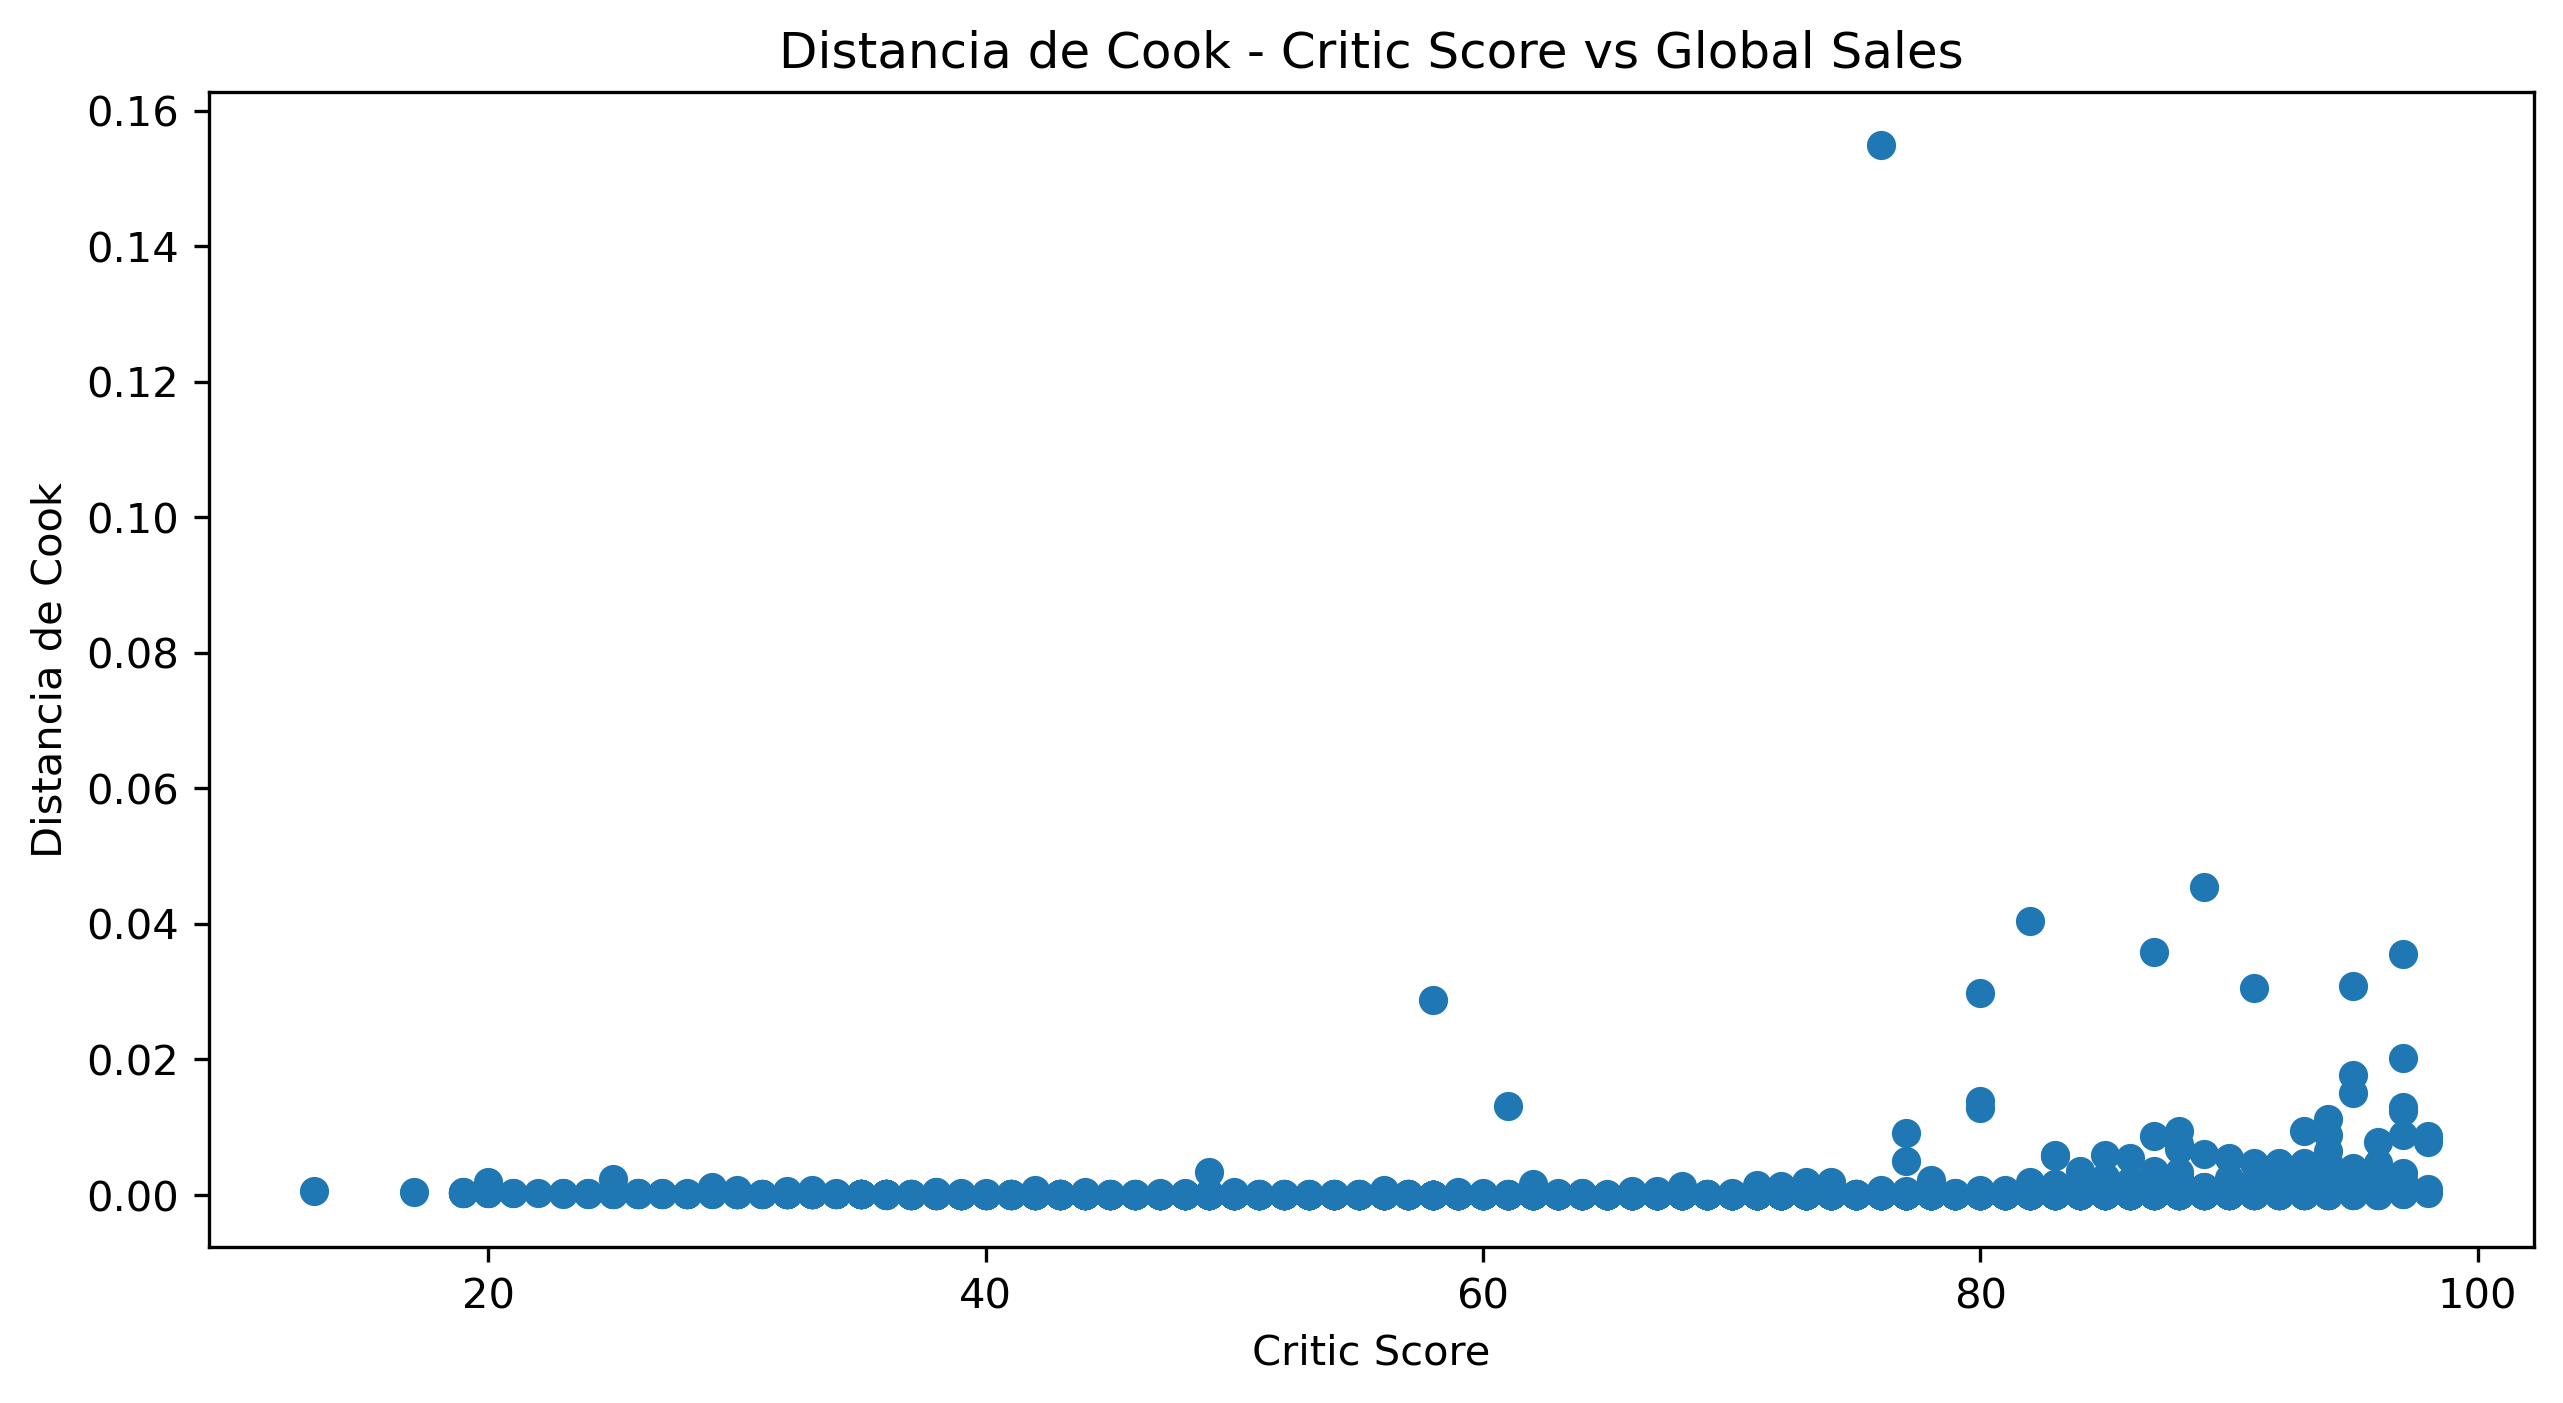

In [46]:
# --- Distancia de Cook: Critic_Score -> Global_Sales ---
y = variables['Global_Sales']
x = sm.add_constant(variables['Critic_Score'])
model = sm.OLS(y, x).fit()

cooks_distance_critic = model.get_influence().cooks_distance[0]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['Critic_Score'], cooks_distance_critic)
ax.set_xlabel('Critic Score')
ax.set_ylabel("Cook's Distance")
ax.set_title("Cook's Distance - Critic Score vs Global Sales")


Text(0.5, 1.0, 'Distancia de Cook - User Score vs Global Sales')

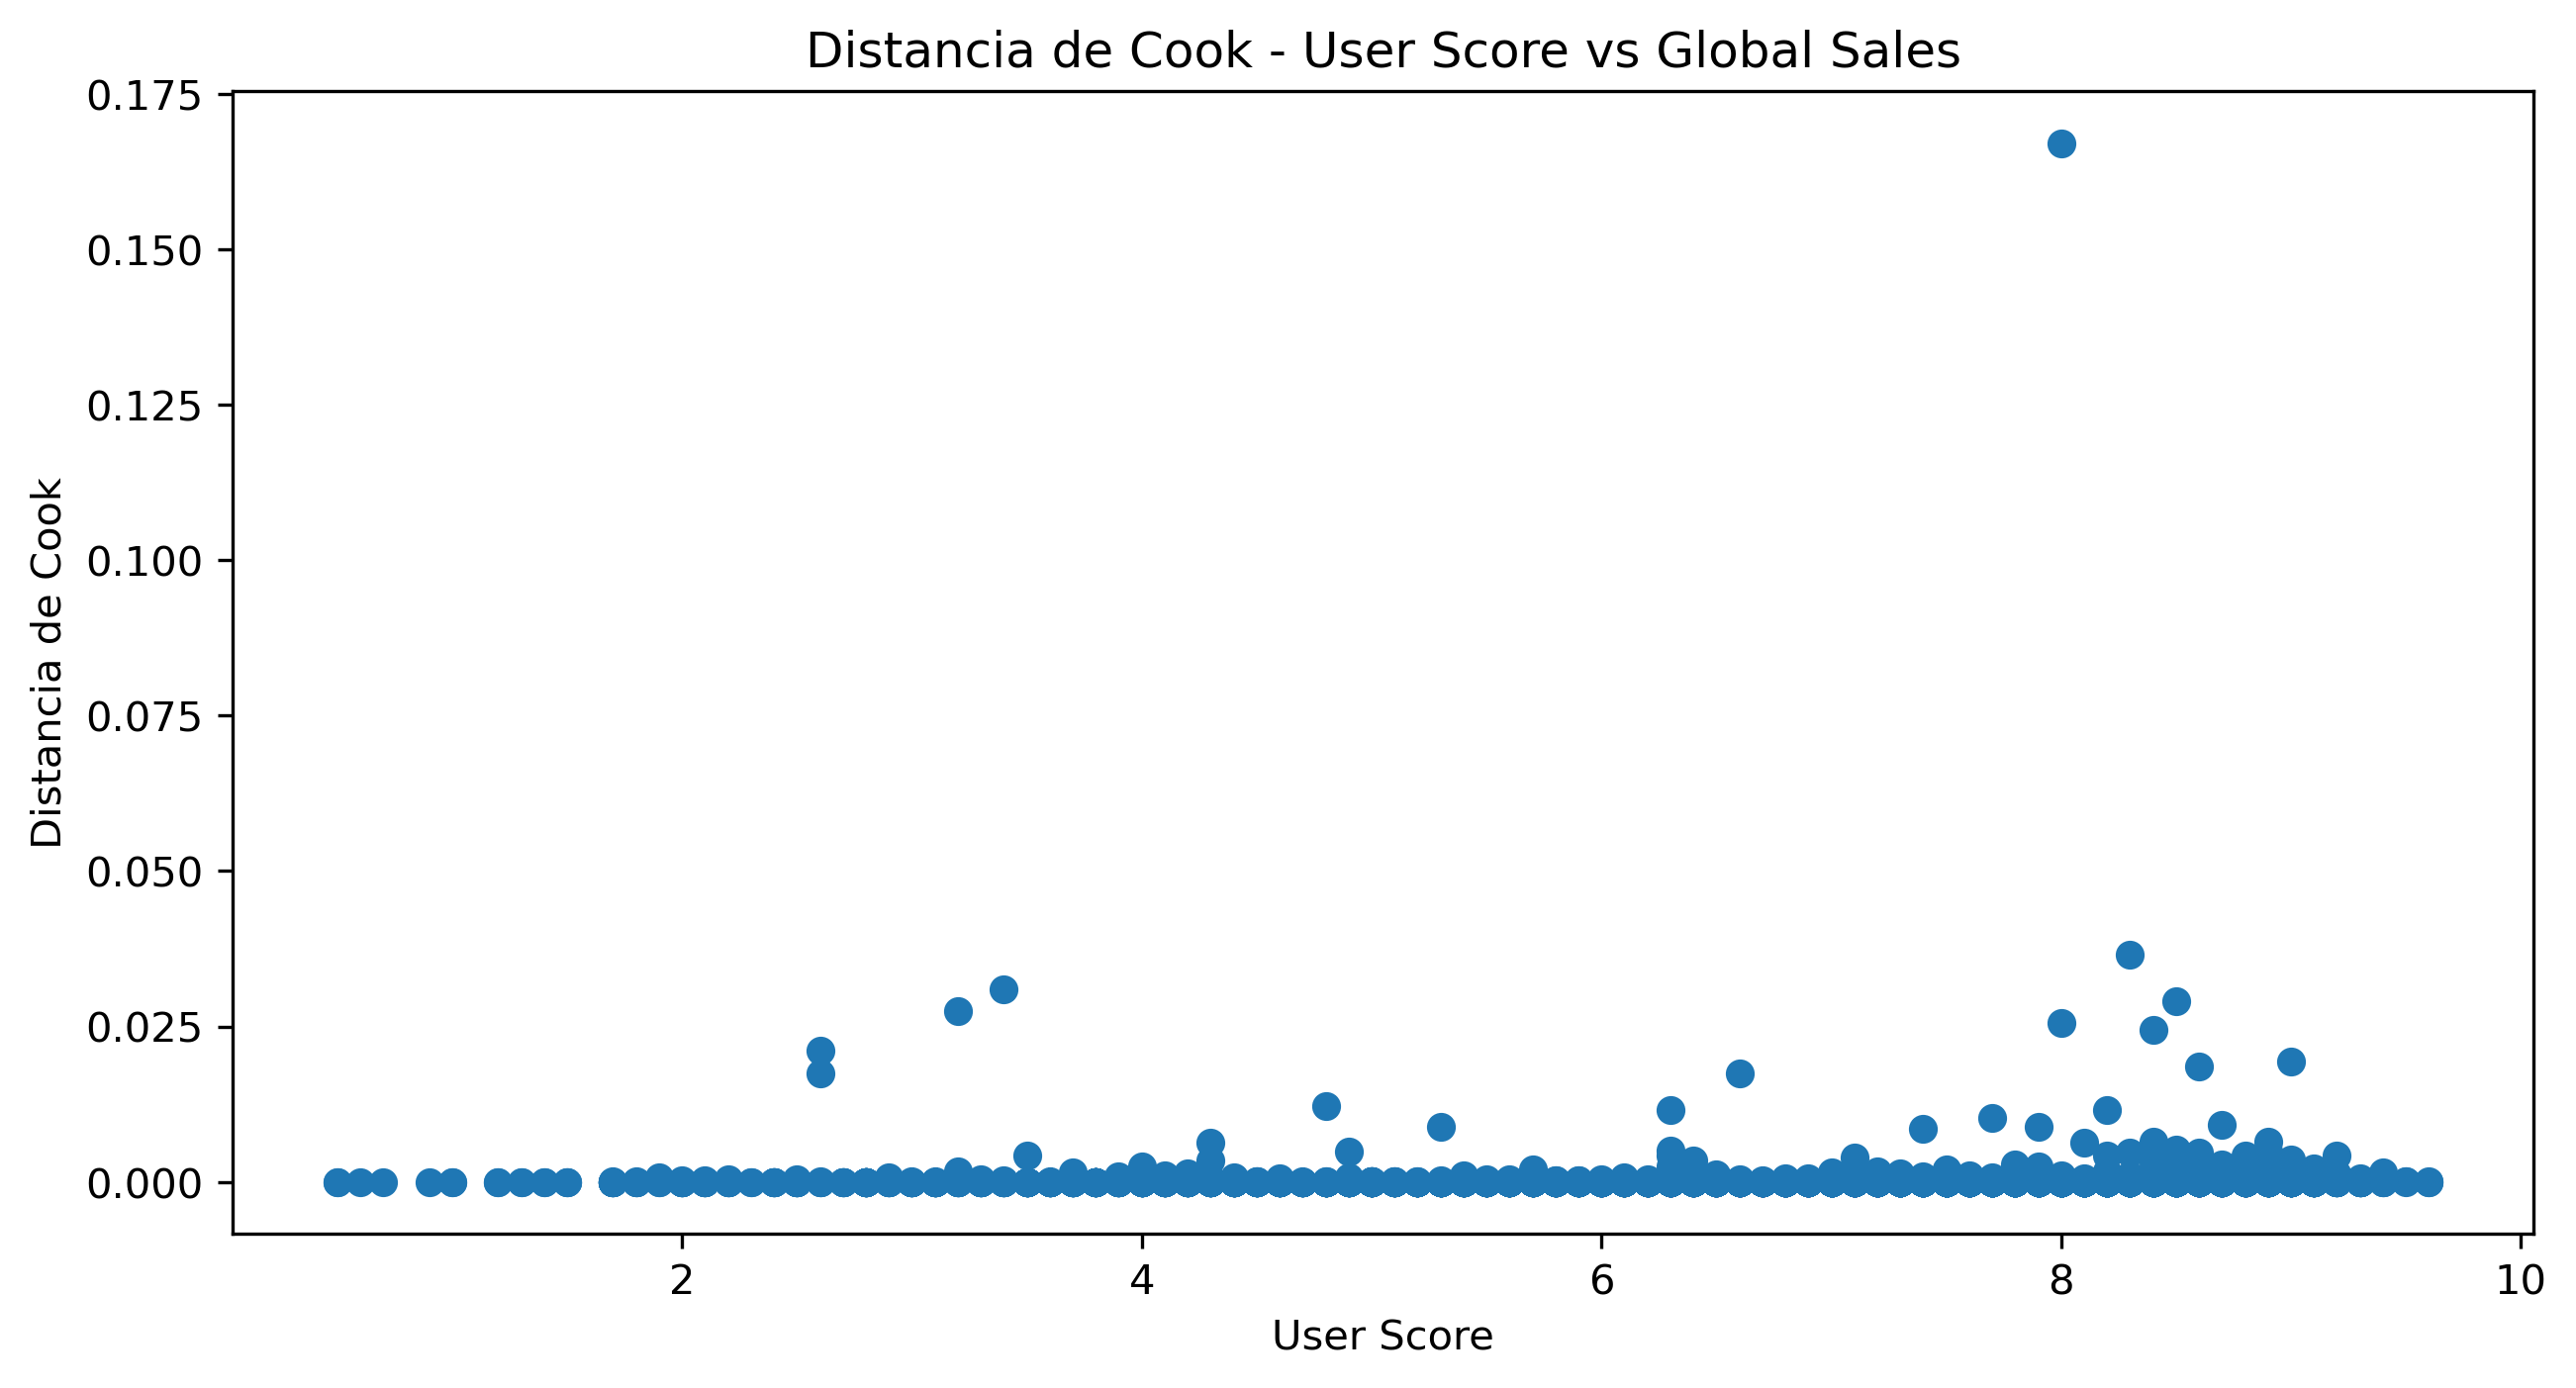

In [47]:
# --- Distancia de Cook: User_Score -> Global_Sales ---
y = variables['Global_Sales']
x = sm.add_constant(variables['User_Score'])
model = sm.OLS(y, x).fit()

cooks_distance_user = model.get_influence().cooks_distance[0]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['User_Score'], cooks_distance_user)
ax.set_xlabel('User Score')
ax.set_ylabel("Cook's Distance")
ax.set_title("Cook's Distance - User Score vs Global Sales")


In [48]:
variables_cook = variables.copy()
variables_cook['Name']        = data['Name']
variables_cook['Cook_critic'] = cooks_distance_critic
variables_cook['Cook_user']   = cooks_distance_user

variables_cook.sort_values(by=['Cook_critic', 'Cook_user'], ascending=False)


,Global_Sales,Critic_Score,User_Score,Name,Cook_critic,Cook_user
0,82.54,76.0,8.0,Wii Sports,1.549610e-01,1.670721e-01
6,29.81,89.0,8.5,New Super Mario Bros.,4.541239e-02,2.903702e-02
2,35.57,82.0,8.3,Mario Kart Wii,4.044439e-02,3.648626e-02
8,28.38,87.0,8.4,New Super Mario Bros. Wii,3.578909e-02,2.451270e-02
16,21.12,97.0,8.2,Grand Theft Auto V,3.557829e-02,1.163149e-02
...,...,...,...,...,...,...
6096,0.29,56.0,7.5,Warriors Orochi 2,6.840577e-11,5.095466e-06
2125,0.98,77.0,7.9,LEGO Harry Potter: Years 5-7,6.233014e-11,4.370905e-07
2113,0.98,77.0,8.2,Tales of Graces f,6.233014e-11,2.877687e-07
8537,0.16,52.0,7.1,NBA Live 08,1.895977e-12,6.581712e-06


## 7.

Analice los residuos de sus modelos. ¿Se cumplen los supuestos de normalidad y homocedasticidad de estos?

Un supuesto importante que se realiza al ajustar una regresion lineal es que los residuos siguen una distribucion Normal con **varianza constante**. En notacion matematica:
$$\varepsilon \sim \mathcal{N}(0, \sigma^2), \quad \sigma^2 \text{ constante}$$

La condicion de varianza constante se llama **homocedasticidad**. Si la varianza cambia segun el valor de $x$, se dice que hay **heterocedasticidad**, lo que invalida algunas propiedades del modelo.

Para verificar estos dos supuestos usaremos:
- **Test de Shapiro-Wilk**: evalua si los residuos siguen una distribucion normal. Si $p < 0.05$, los residuos no son normales.
- **Test de Breusch-Pagan**: evalua si la varianza de los residuos es constante. Si $p < 0.05$, existe heterocedasticidad.

El **Q-Q plot** complementa el test de Shapiro-Wilk de forma visual: si los puntos siguen la linea roja, el supuesto de normalidad se cumple.


/Users/gabbi/miniconda3/envs/SaaLab/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7191.
  res = hypotest_fun_out(*samples, **kwds)


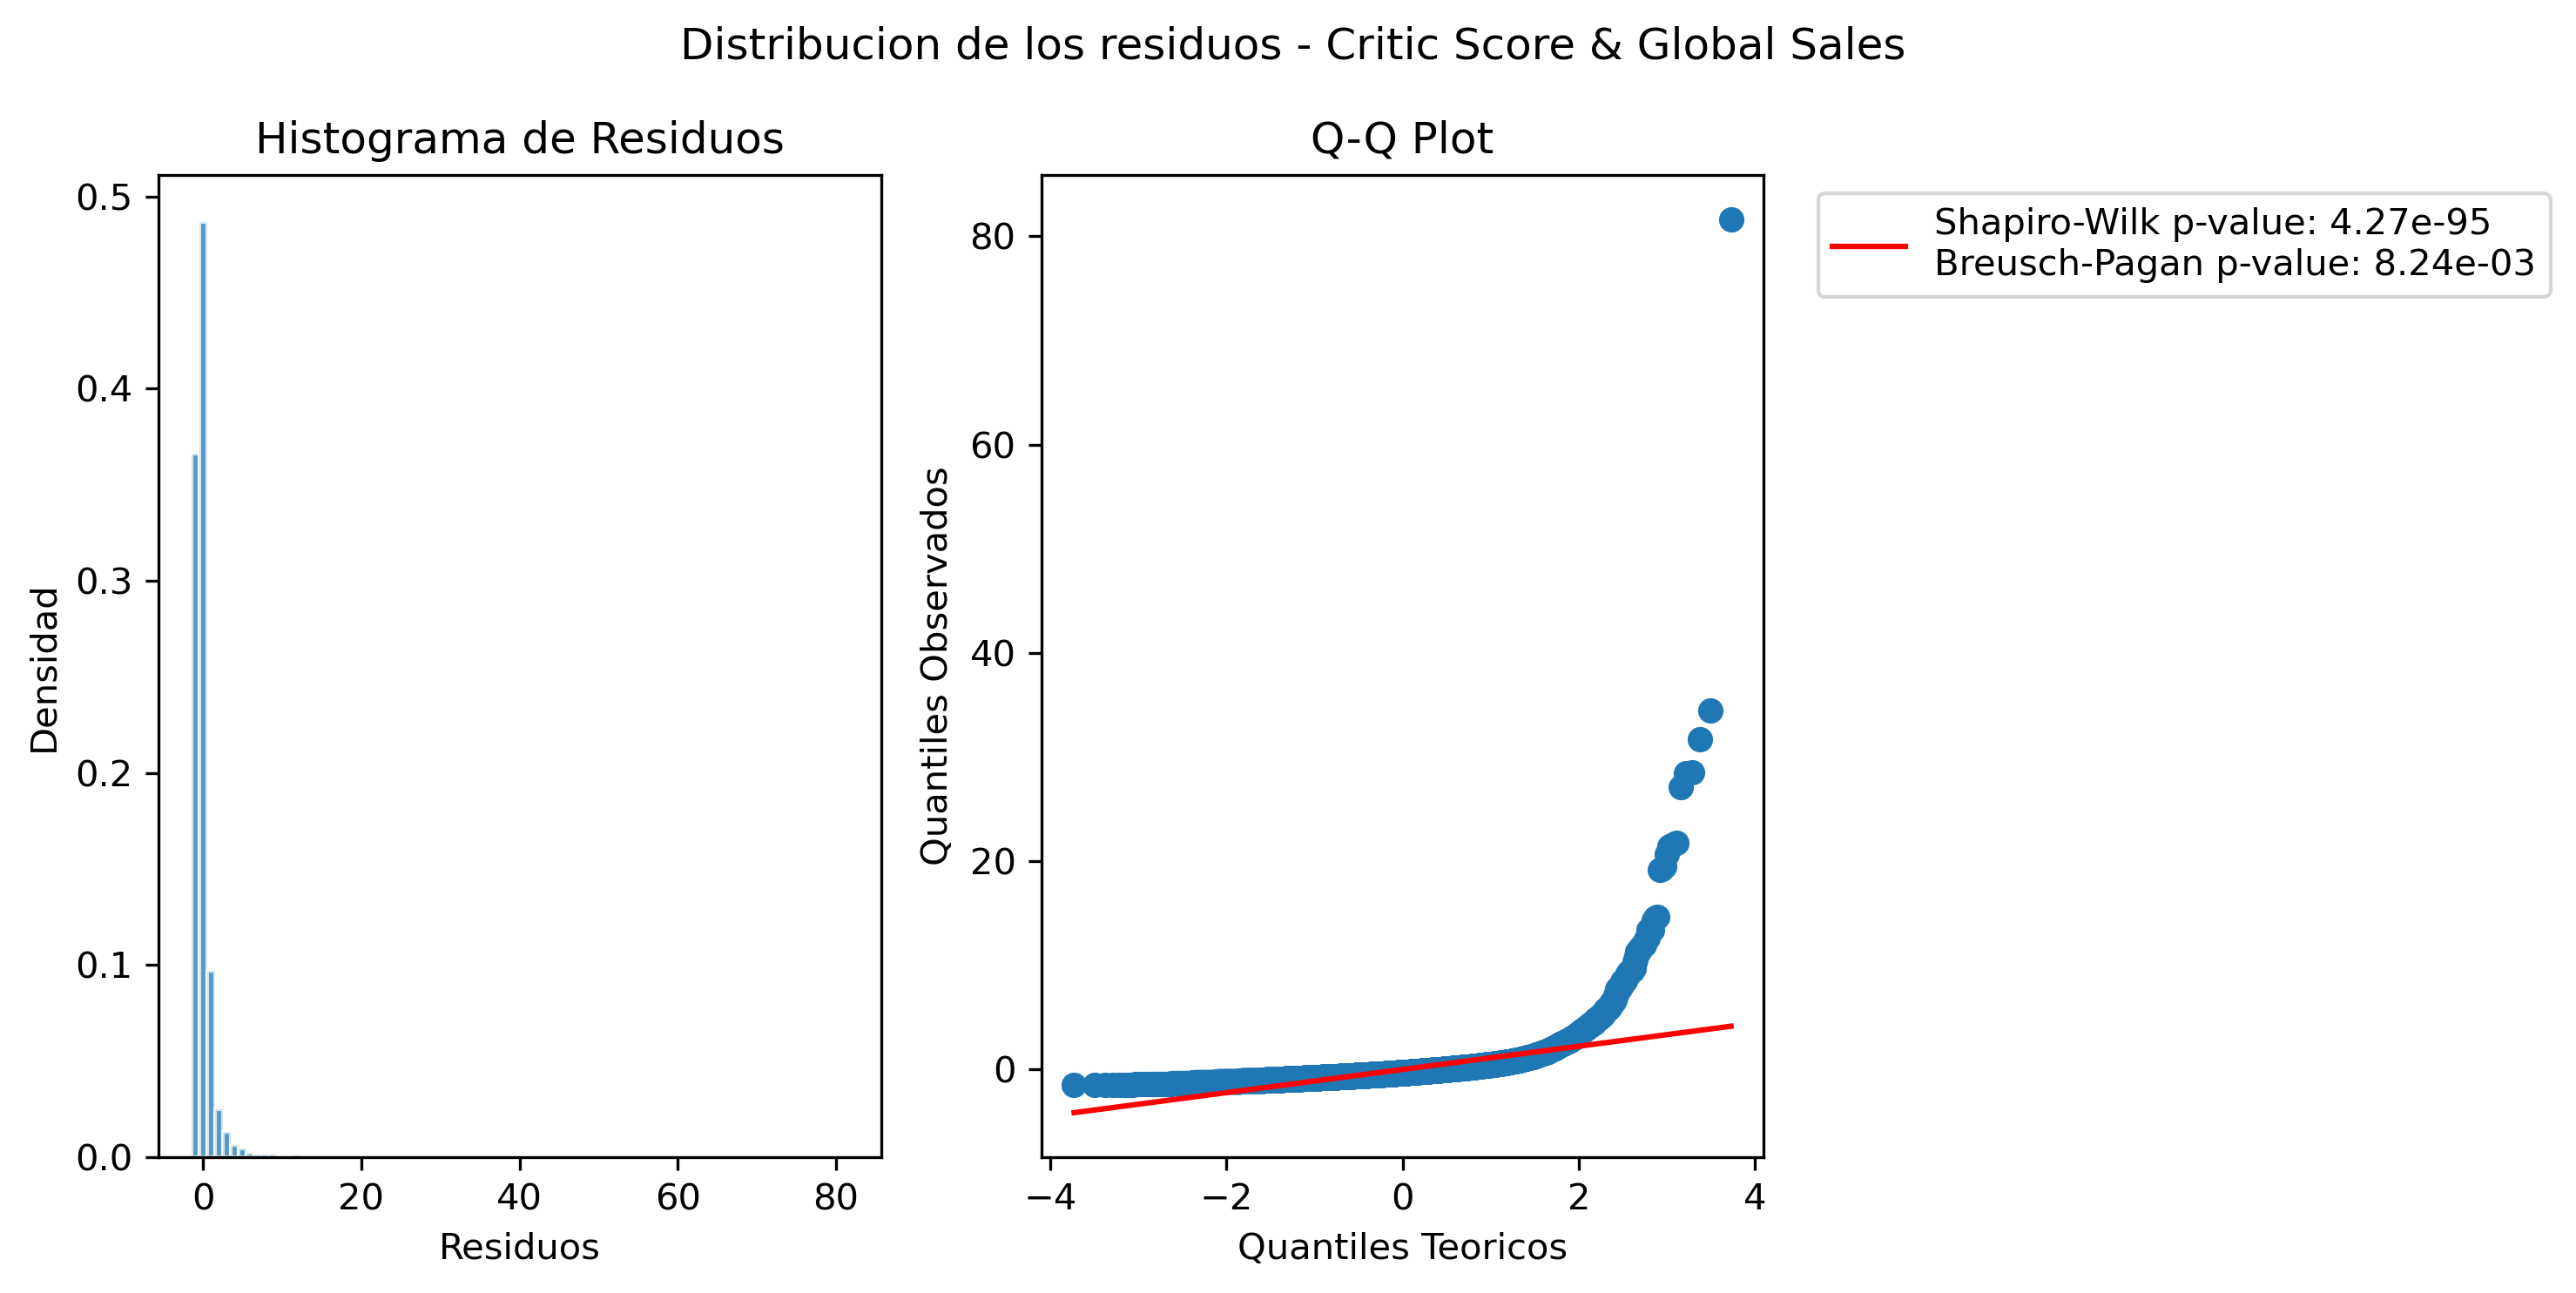

In [49]:
from statsmodels.stats.diagnostic import het_breuschpagan

# --- Residuos: Critic_Score -> Global_Sales ---
x = sm.add_constant(variables['Critic_Score'])
y = variables['Global_Sales']
model = sm.OLS(y, x).fit()
residuals = model.resid

# H0 Shapiro-Wilk: residuos normales       (p < 0.05 -> no normales)
# H0 Breusch-Pagan: varianza constante     (p < 0.05 -> heterocedasticidad)
shapiro_p = st.shapiro(residuals)[1]
_, bp_p, _, _ = het_breuschpagan(residuals, model.model.exog)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].hist(residuals, bins=int(np.sqrt(len(residuals))), density=True, alpha=0.75, edgecolor='white')
ax[0].set_xlabel('Residuos')
ax[0].set_ylabel('Densidad')
ax[0].set_title('Histograma de Residuos')

(osm, osr), (slope, intercept, r) = st.probplot(residuals, dist="norm")
ax[1].scatter(osm, osr)
ax[1].plot(osm, slope * osm + intercept, color='red',
           label=f'Shapiro-Wilk p={shapiro_p:.2e}\nBreusch-Pagan p={bp_p:.2e}')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax[1].set_xlabel('Quantiles Teoricos')
ax[1].set_ylabel('Quantiles Observados')
ax[1].set_title('Q-Q Plot')

fig.suptitle('Residuos - Critic Score & Global Sales')
plt.tight_layout()


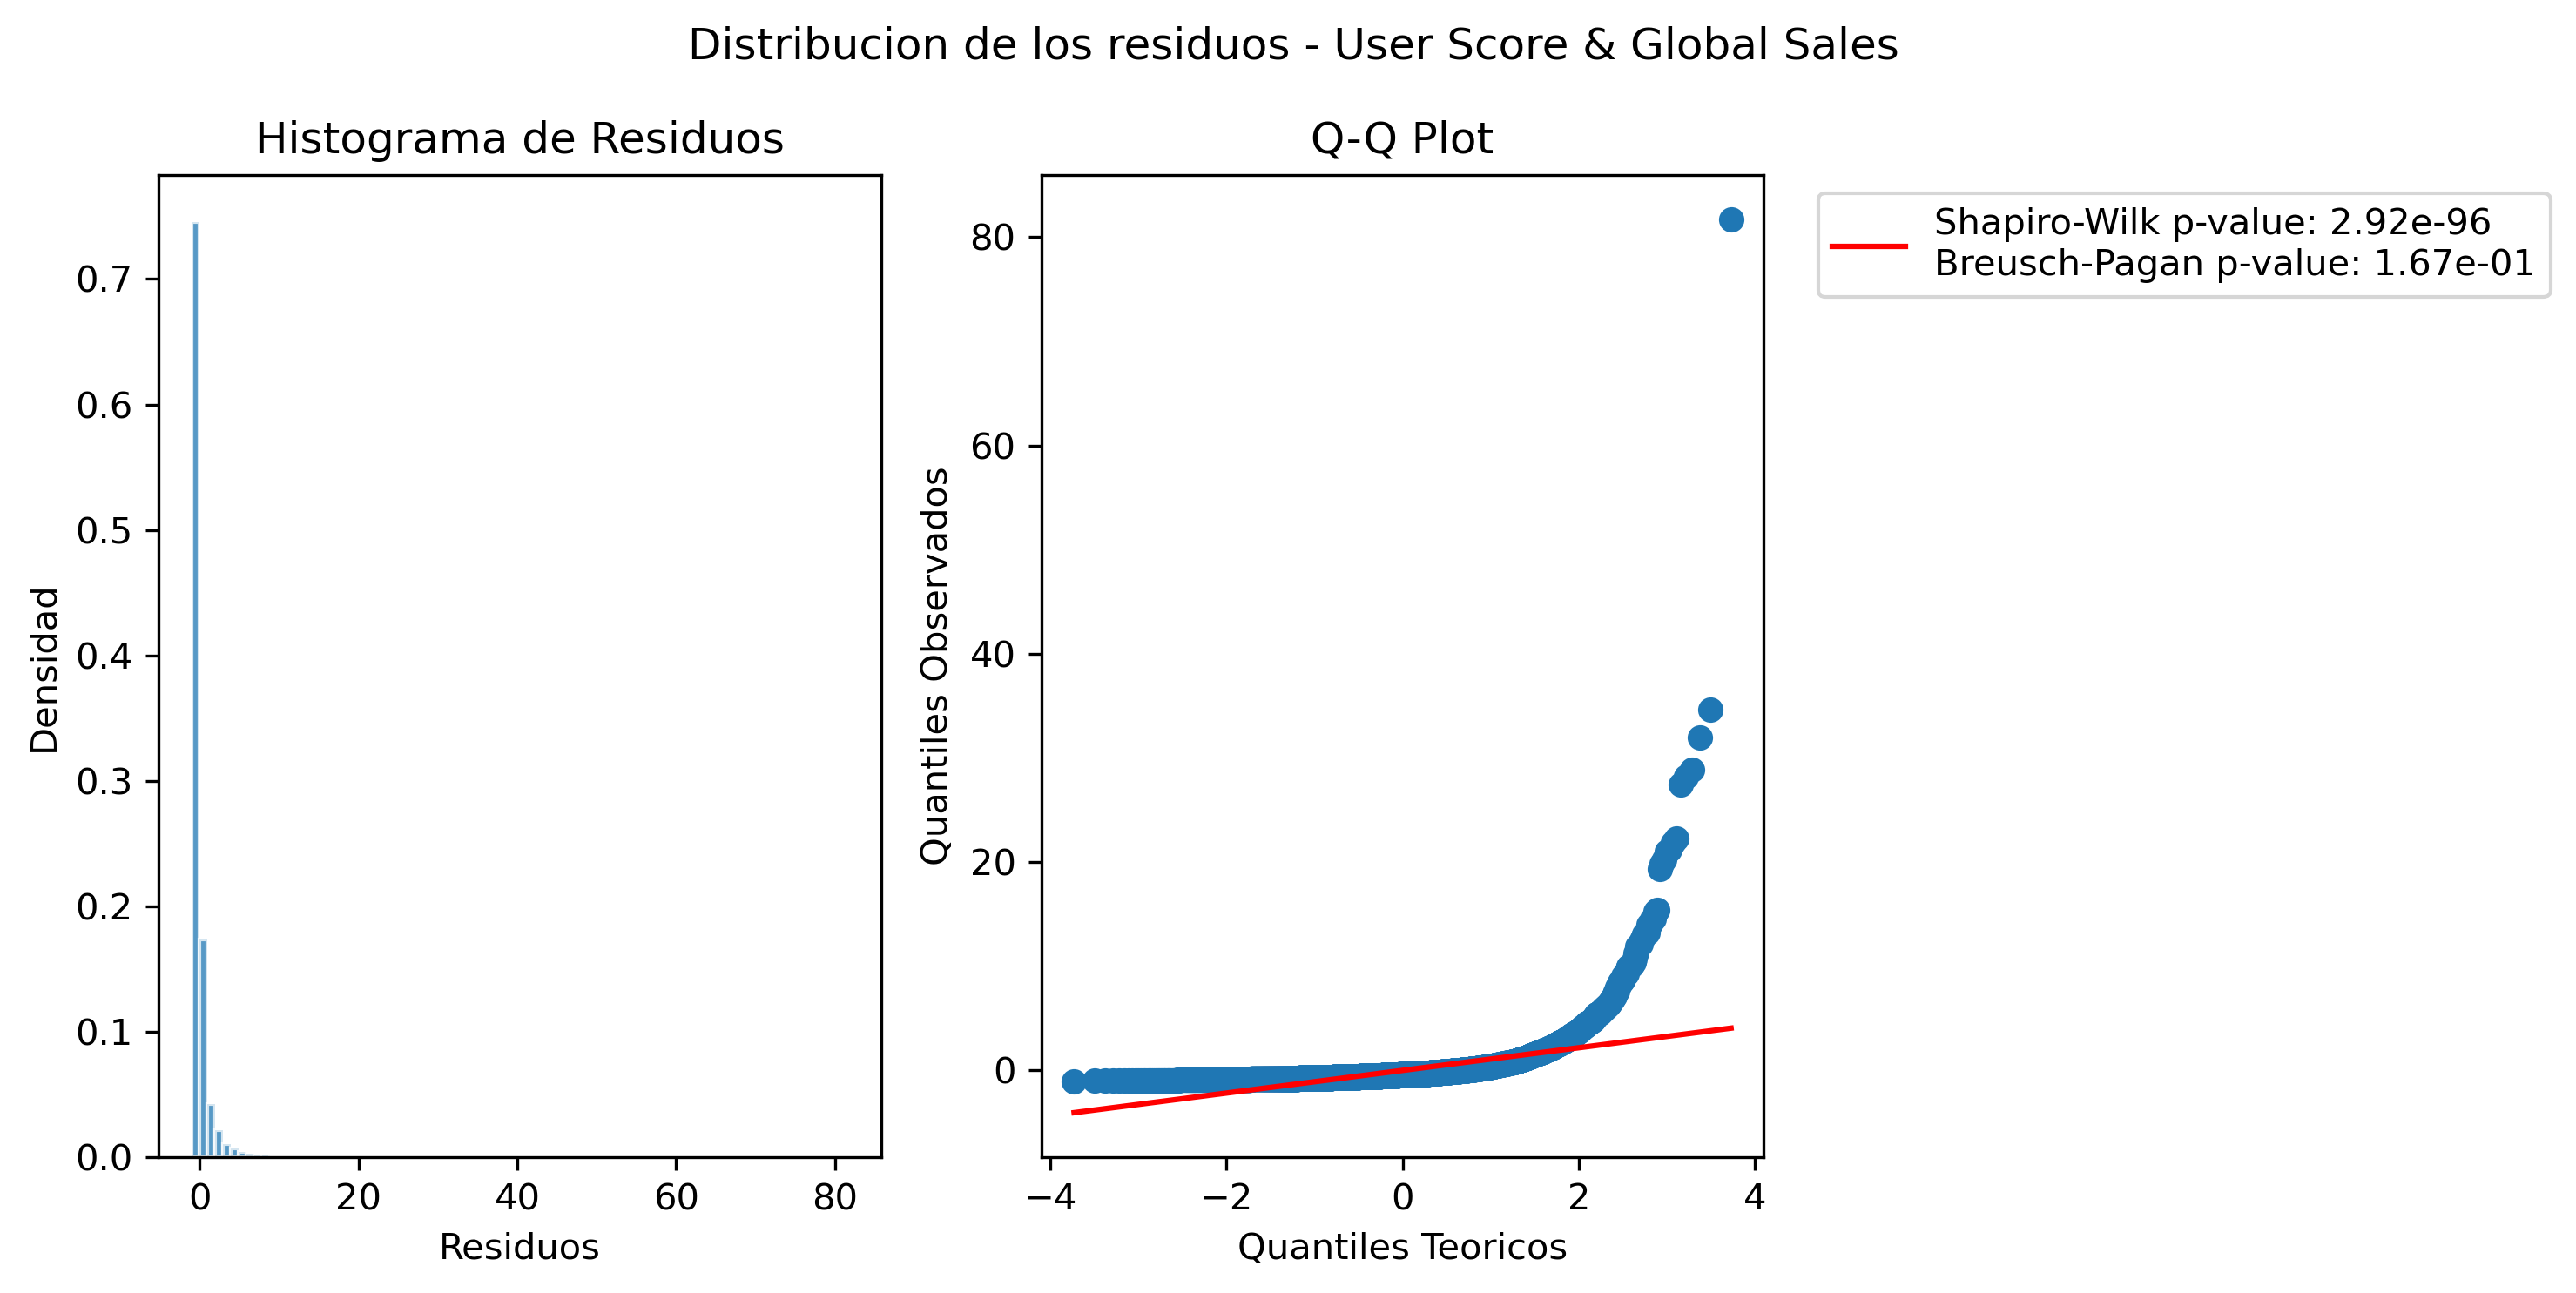

In [50]:
# --- Residuos: User_Score -> Global_Sales ---
x = sm.add_constant(variables['User_Score'])
y = variables['Global_Sales']
model = sm.OLS(y, x).fit()
residuals = model.resid

shapiro_p = st.shapiro(residuals)[1]
_, bp_p, _, _ = het_breuschpagan(residuals, model.model.exog)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].hist(residuals, bins=int(np.sqrt(len(residuals))), density=True, alpha=0.75, edgecolor='white')
ax[0].set_xlabel('Residuos')
ax[0].set_ylabel('Densidad')
ax[0].set_title('Histograma de Residuos')

(osm, osr), (slope, intercept, r) = st.probplot(residuals, dist="norm")
ax[1].scatter(osm, osr)
ax[1].plot(osm, slope * osm + intercept, color='red',
           label=f'Shapiro-Wilk p={shapiro_p:.2e}\nBreusch-Pagan p={bp_p:.2e}')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax[1].set_xlabel('Quantiles Teoricos')
ax[1].set_ylabel('Quantiles Observados')
ax[1].set_title('Q-Q Plot')

fig.suptitle('Residuos - User Score & Global Sales')
plt.tight_layout()
plt.show()


### Interpretación de los diagnósticos

Con los resultados anteriores podemos concluir:

- **Shapiro-Wilk p < 0.05**: los residuos **no** son normales. El Q-Q plot muestra colas pesadas (muchos puntos alejados de la línea roja).
- **Breusch-Pagan p < 0.05**: existe **heterocedasticidad** — la varianza de los residuos no es constante.

Ambos supuestos se violan porque `Global_Sales` es una variable muy sesgada: la mayoría de los juegos venden muy poco, pero unos pocos venden enormemente (e.g. Wii Sports: 82.54M). Este comportamiento es típico de datos económicos y se suele tratar con una **transformación logarítmica**.

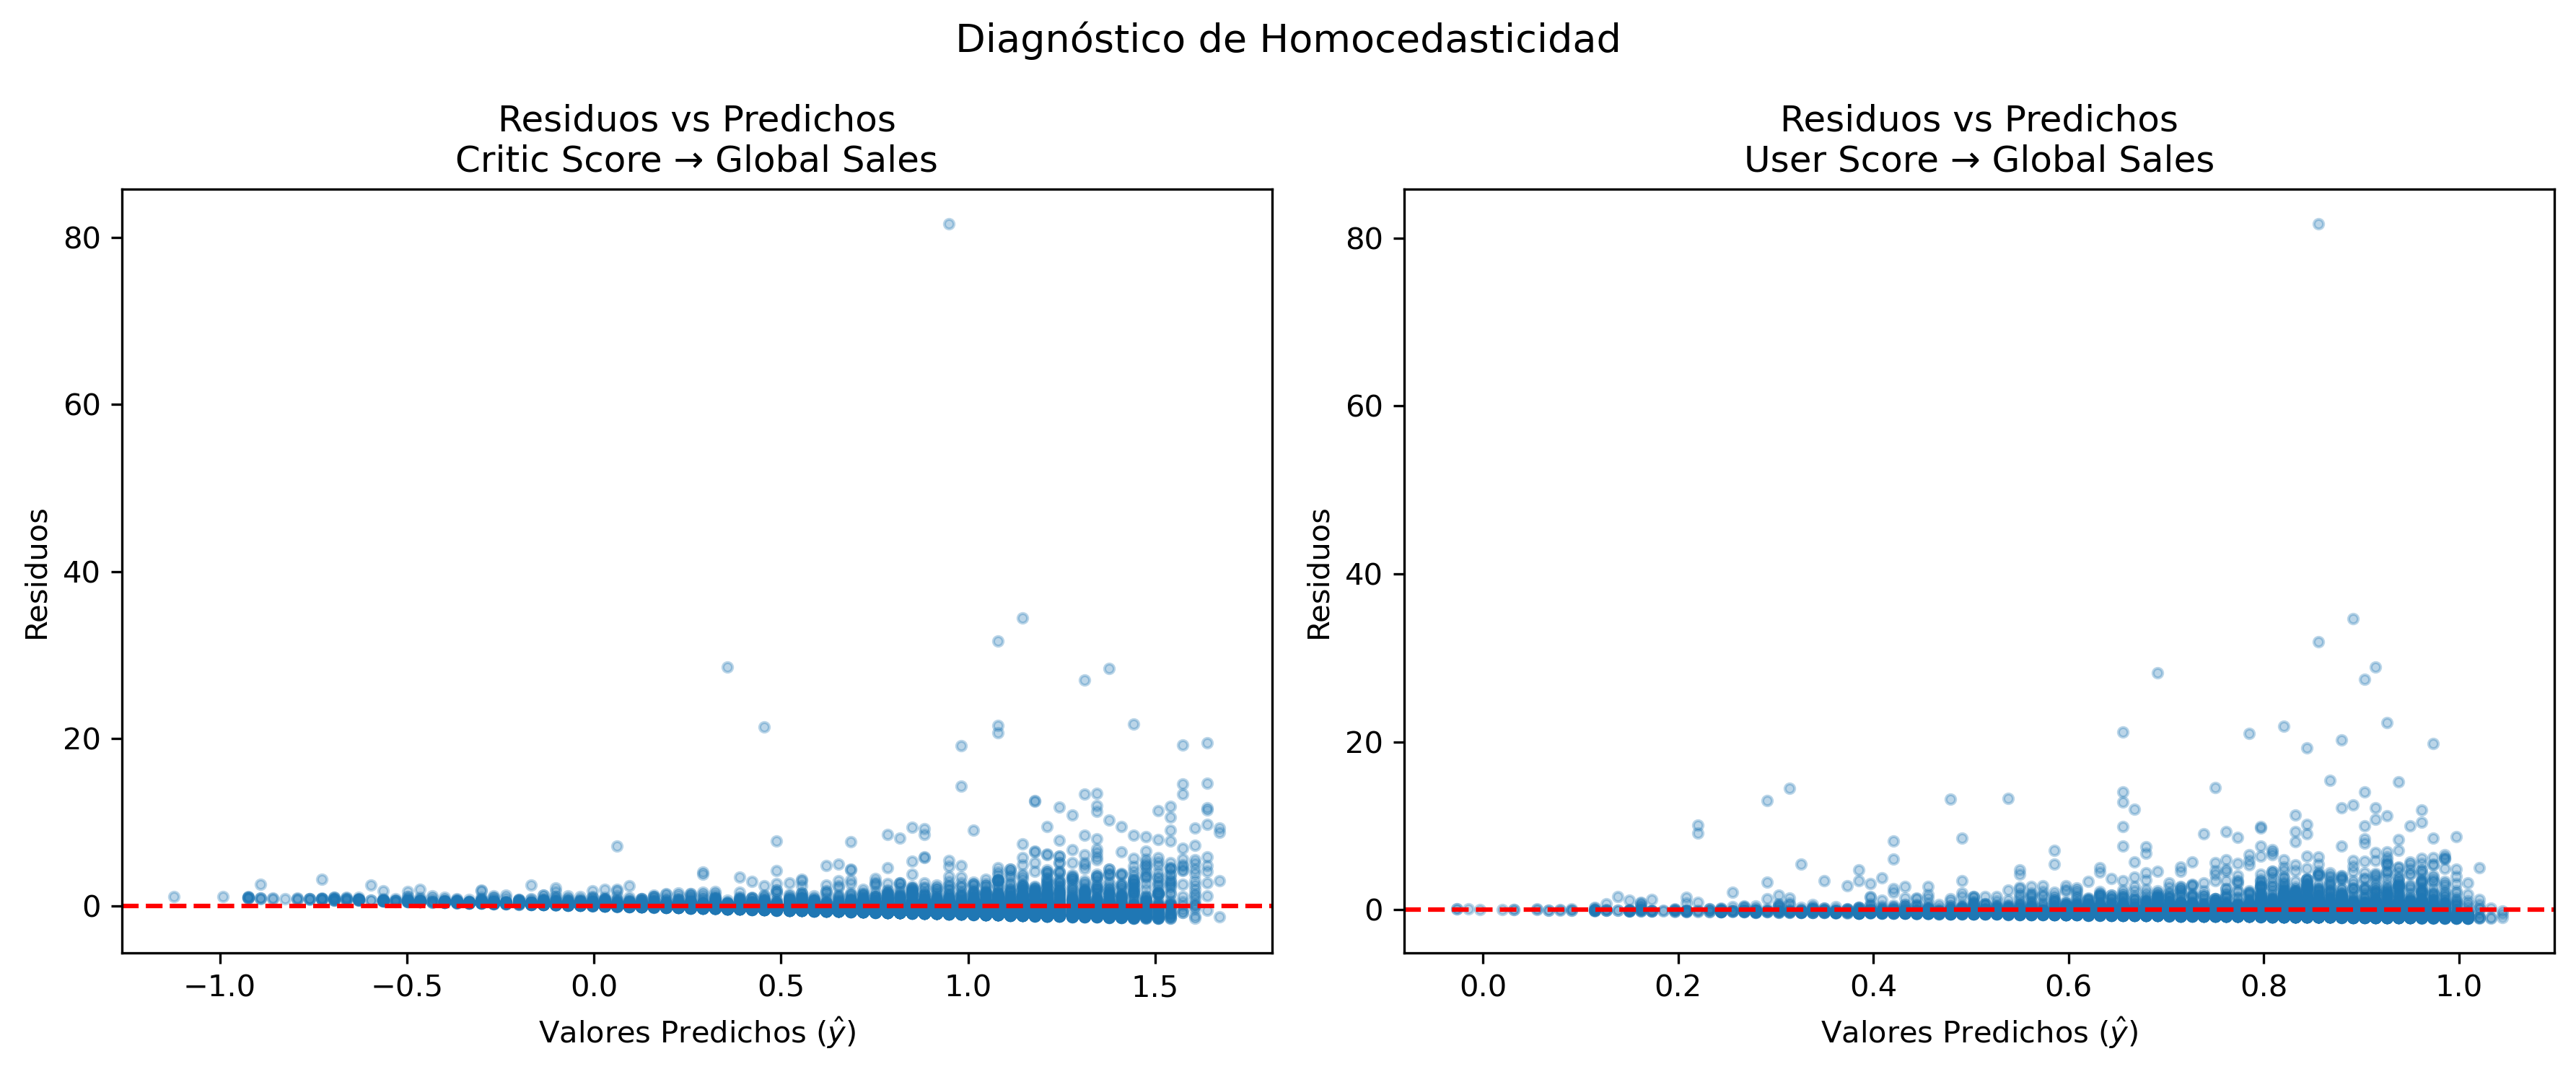

In [51]:
# Residuos vs predichos: patron de embudo = heterocedasticidad
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

for ax, x_col, title in zip(
    axes,
    ['Critic_Score', 'User_Score'],
    ['Critic Score -> Global Sales', 'User Score -> Global Sales']
):
    model_tmp = sm.OLS(variables['Global_Sales'], sm.add_constant(variables[x_col])).fit()
    ax.scatter(model_tmp.fittedvalues, model_tmp.resid, alpha=0.3, s=10)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Valores Predichos')
    ax.set_ylabel('Residuos')
    ax.set_title(f'Residuos vs Predichos\n{title}')

fig.suptitle('Diagnostico de Homocedasticidad', fontsize=13)
plt.tight_layout()
plt.show()


## 8.

Replique su análisis pero ahora relacionando `Critic_Score` y `User_Score`. ¿Qué puede decir?

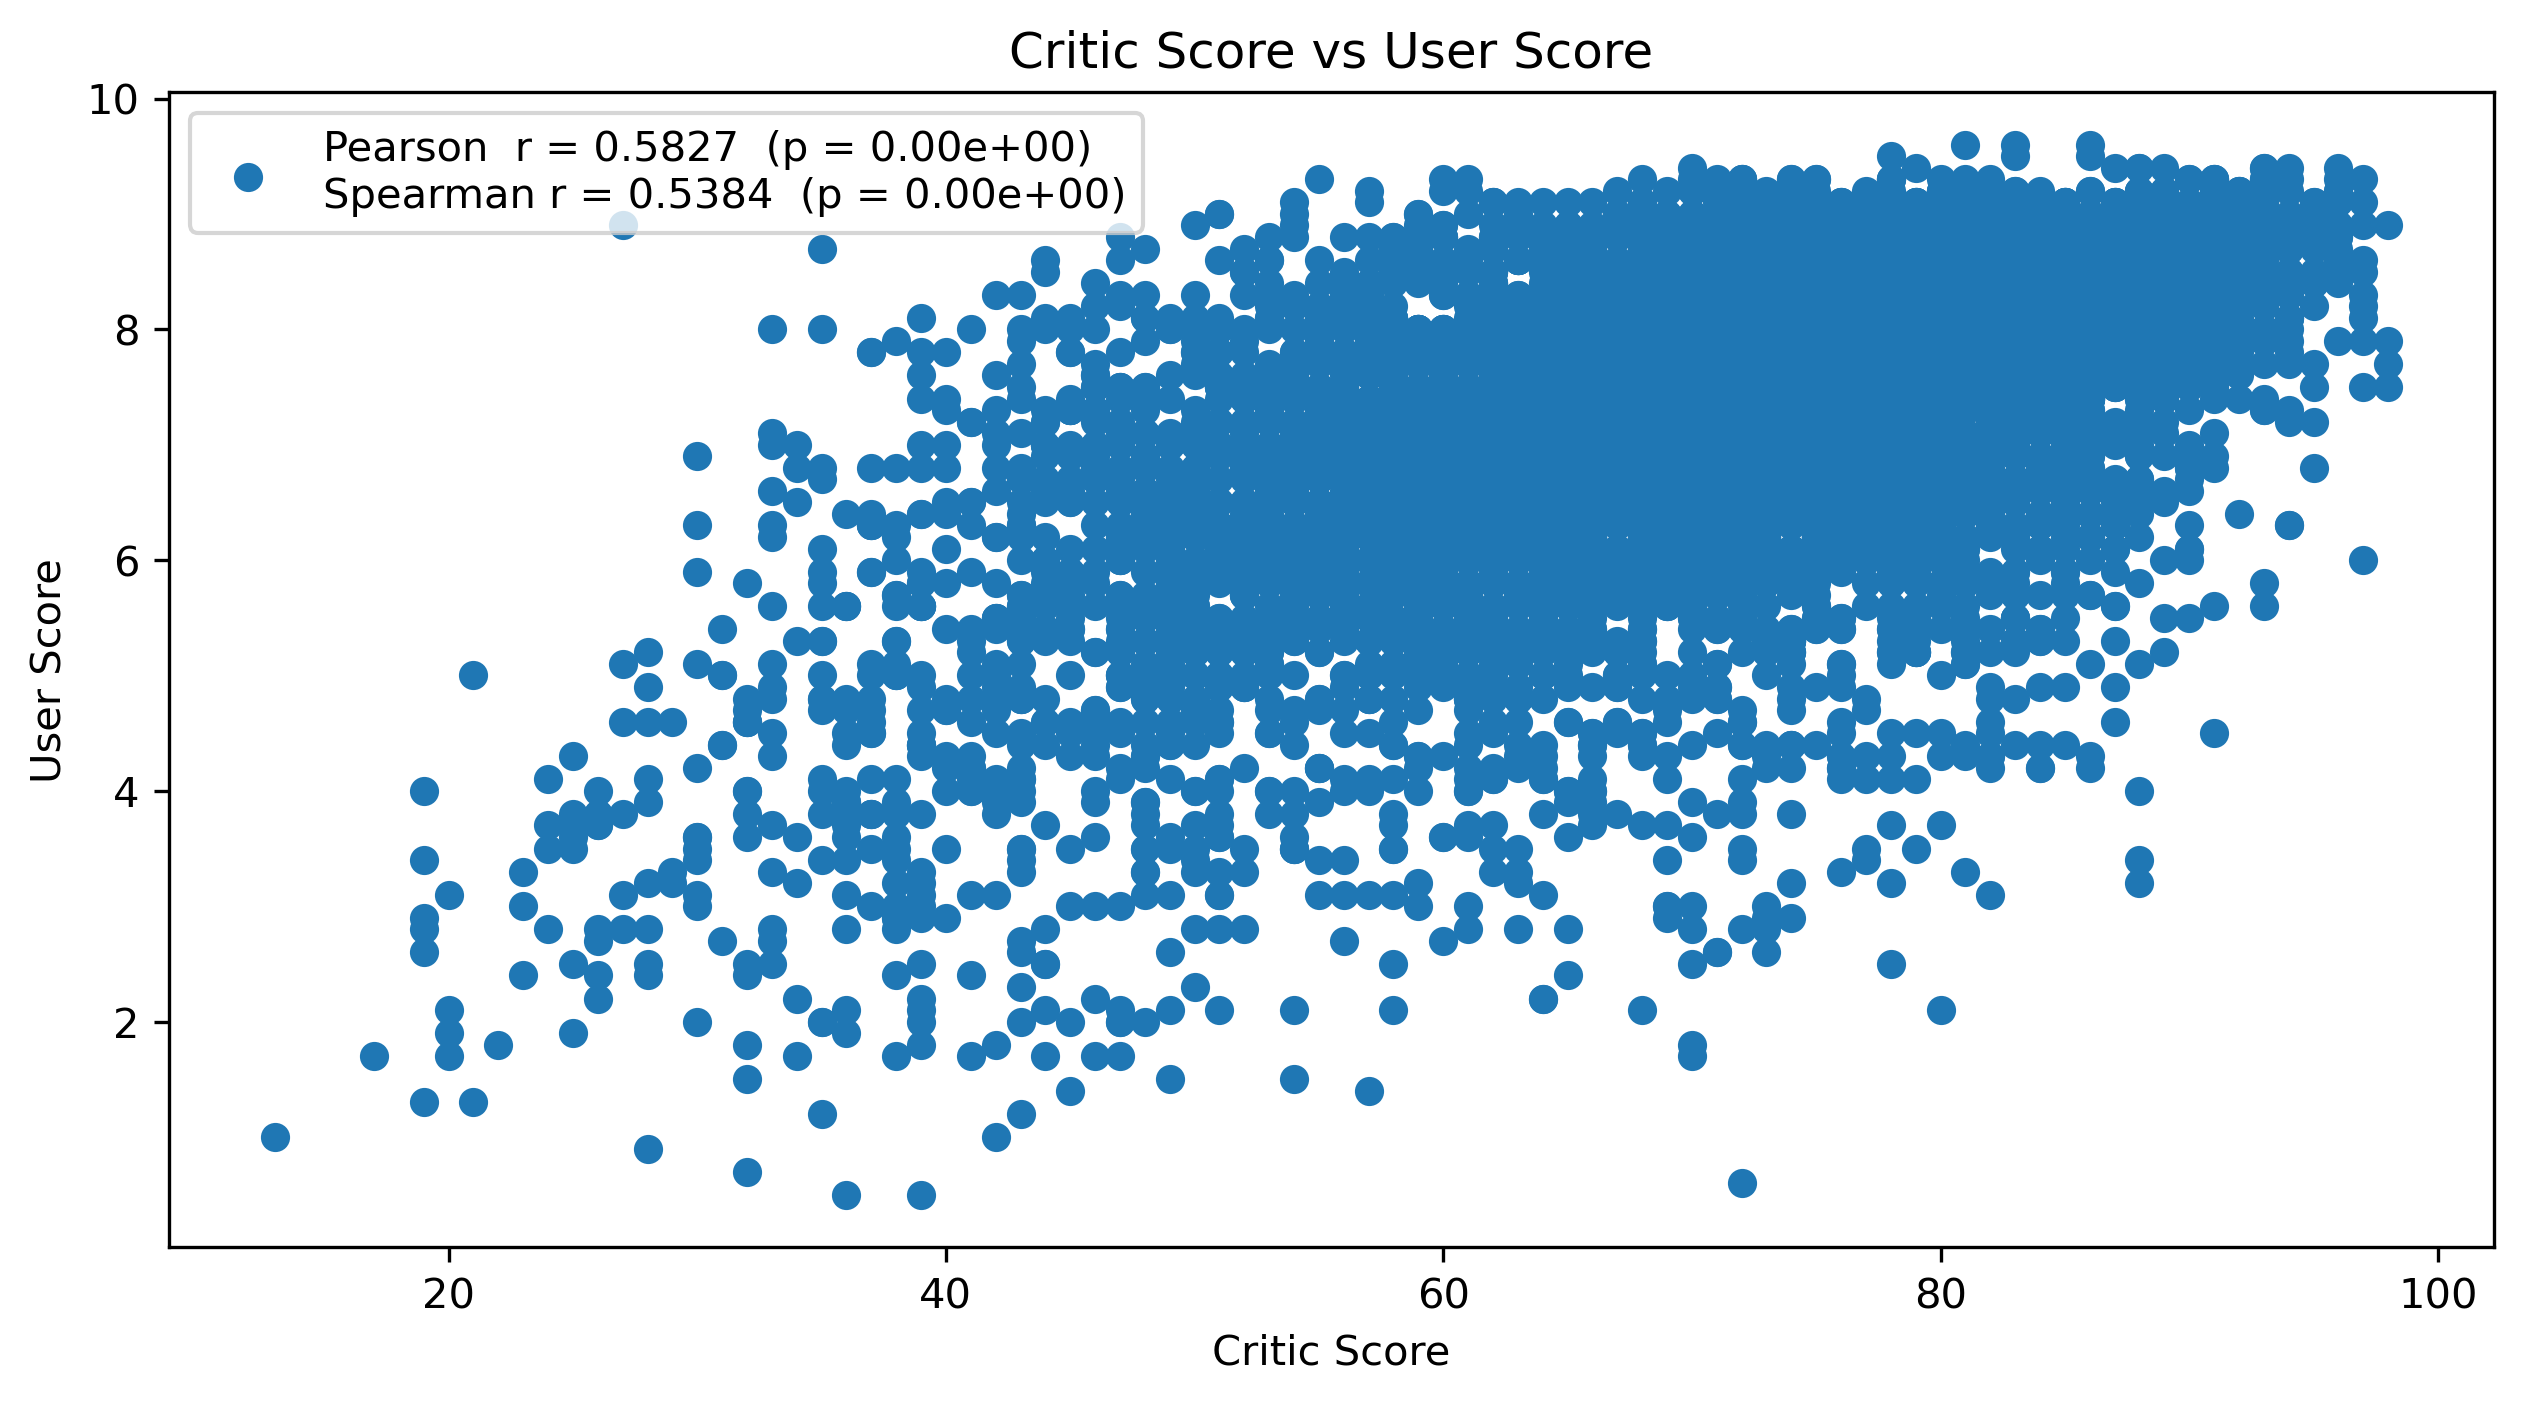

In [52]:
x = variables['Critic_Score']
y = variables['User_Score']

pearson_corr,  pearson_pval  = st.pearsonr(x, y)
spearman_corr, spearman_pval = st.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(x, y, label=(f'Pearson  r={pearson_corr:.4f}  (p={pearson_pval:.2e})\n'
                         f'Spearman r={spearman_corr:.4f}  (p={spearman_pval:.2e})'))
ax.legend()
ax.set_xlabel('Critic Score')
ax.set_ylabel('User Score')
ax.set_title('Critic Score vs User Score')
plt.show()


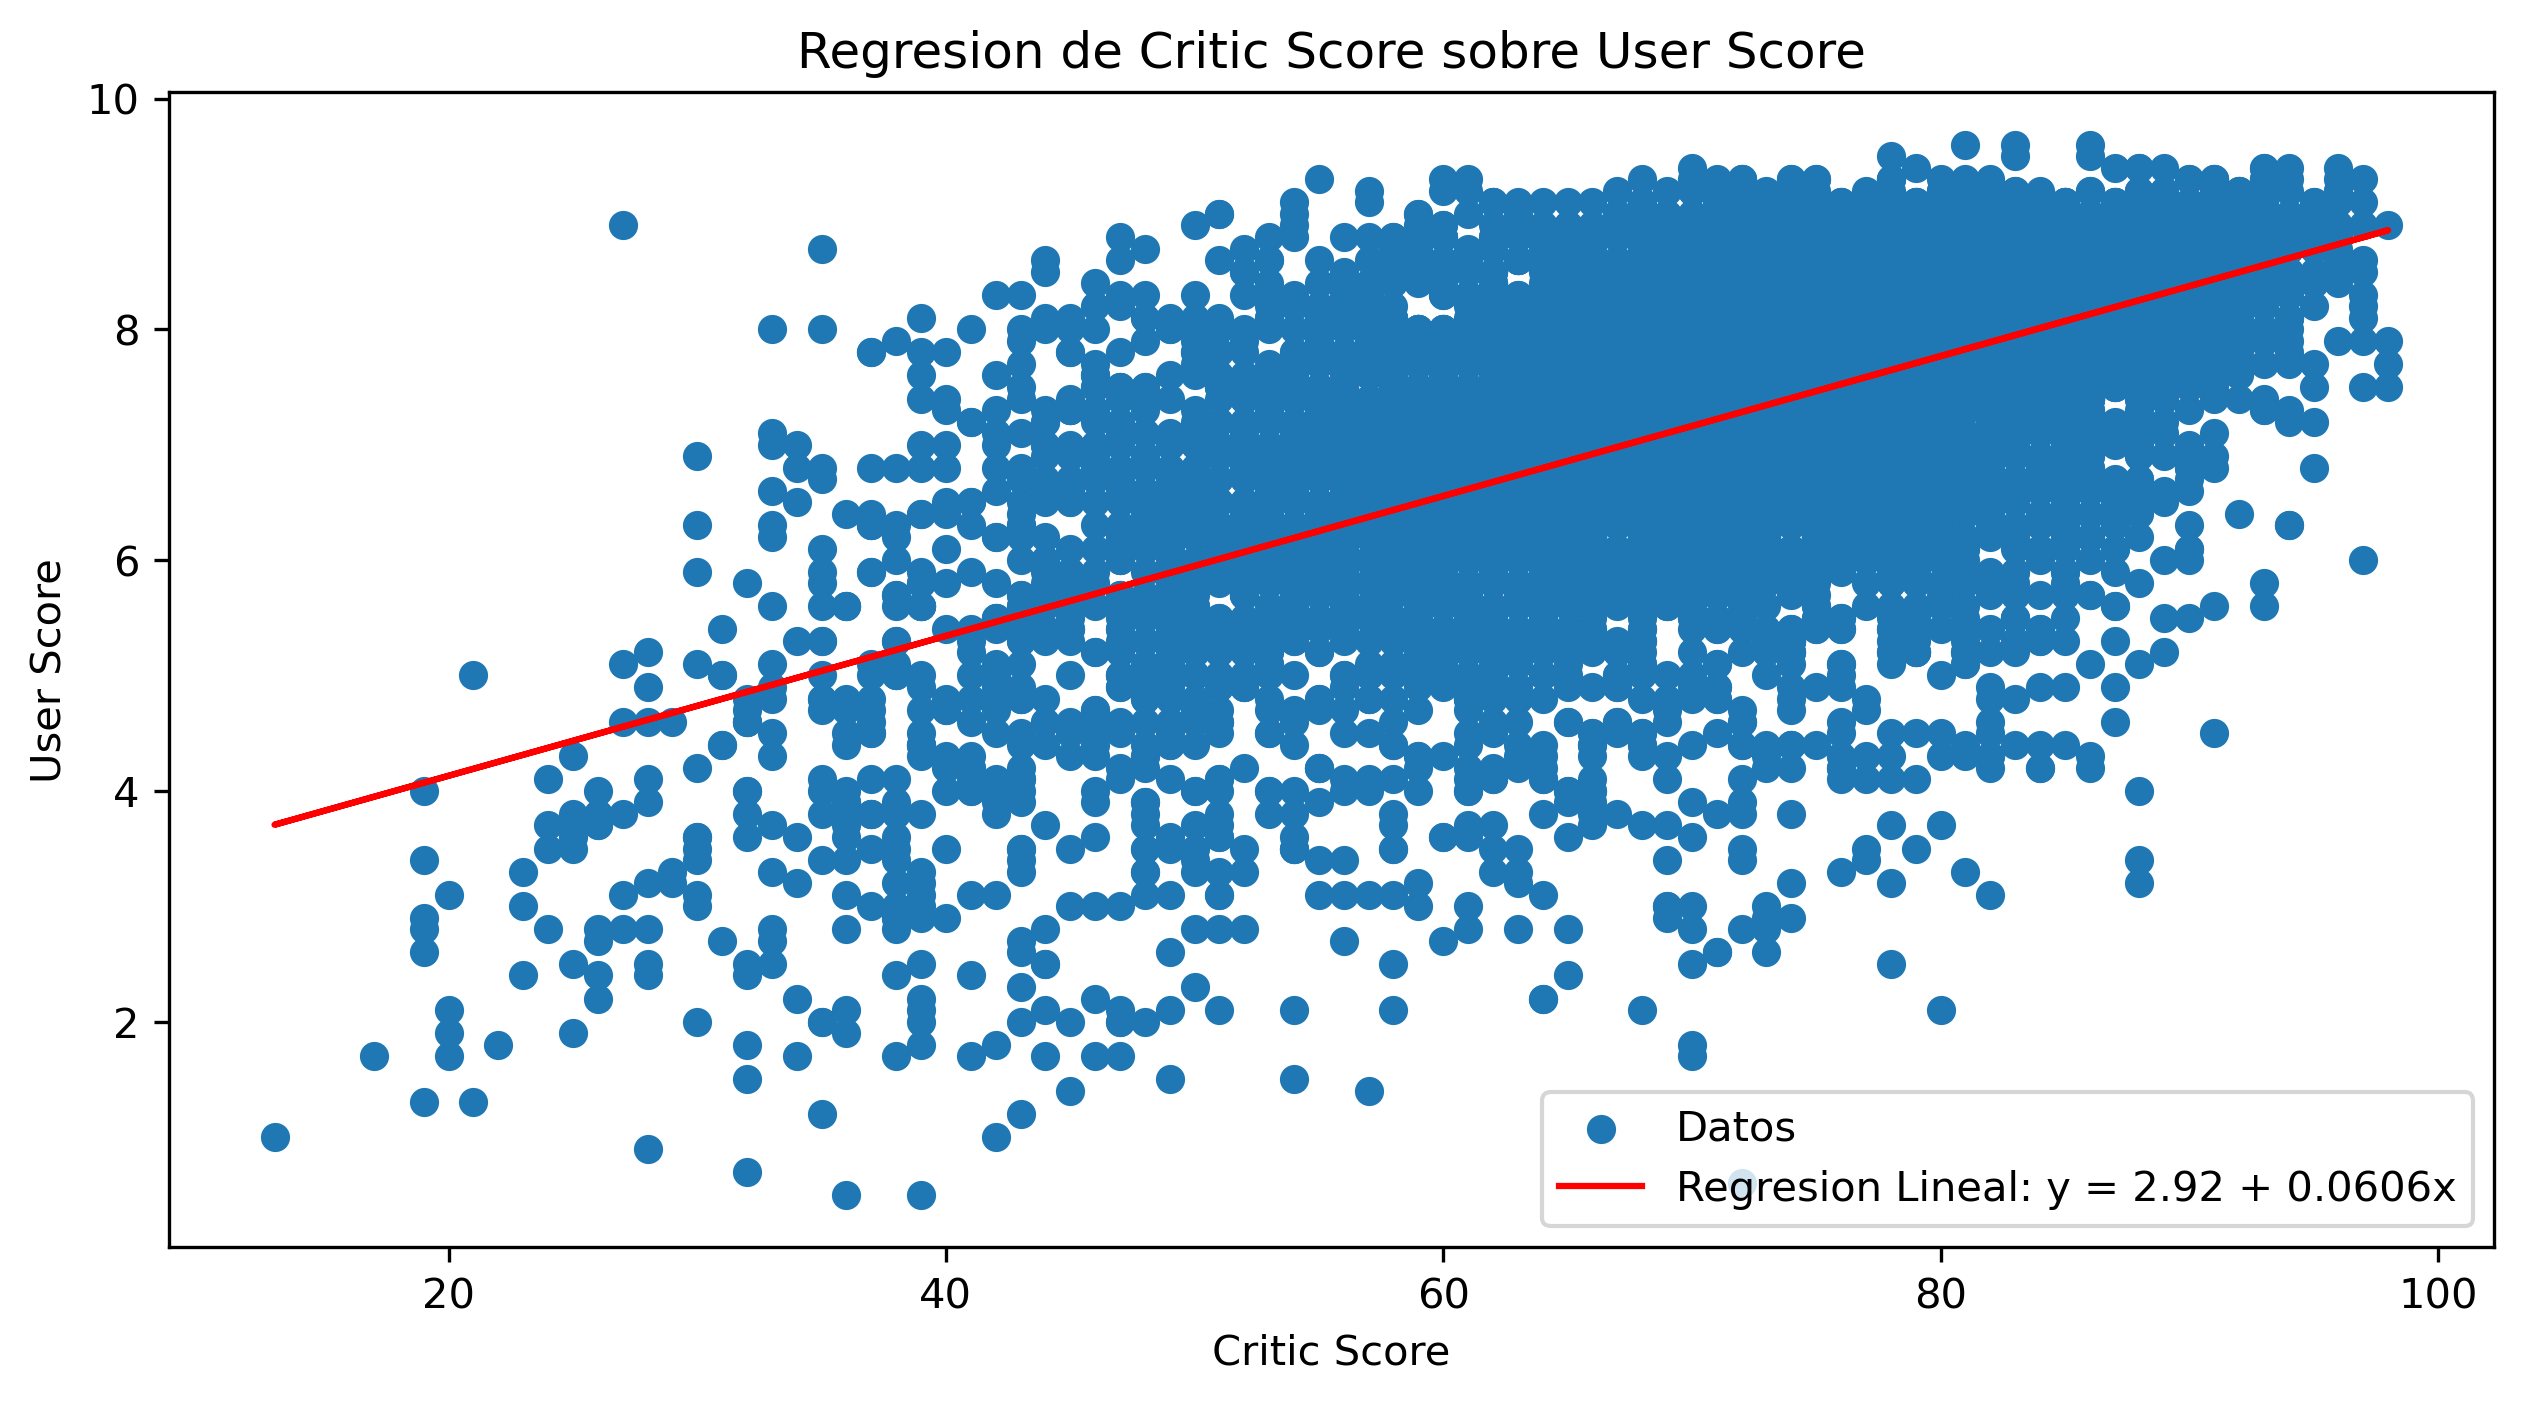

In [53]:
y = variables['User_Score']
x = sm.add_constant(variables['Critic_Score'])
model = sm.OLS(y, x).fit()
beta_0, beta_1 = model.params

y_hat = beta_0 + beta_1 * variables['Critic_Score']

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['Critic_Score'], variables['User_Score'], label='Datos')
ax.plot(variables['Critic_Score'], y_hat, color='red',
        label=f'y = {beta_0:.2f} + {beta_1:.4f}x')
ax.set_xlabel('Critic Score')
ax.set_ylabel('User Score')
ax.set_title('Regresion: Critic Score -> User Score')
ax.legend()
plt.show()


In [54]:
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             User_Score   R-squared:                       0.340
Model:                            OLS   Adj. R-squared:                  0.339
Method:                 Least Squares   F-statistic:                     3696.
Date:                Mon, 20 Apr 2026   Prob (F-statistic):               0.00
Time:                        00:27:20   Log-Likelihood:                -11355.
No. Observations:                7191   AIC:                         2.271e+04
Df Residuals:                    7189   BIC:                         2.273e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            2.9179      0.071     40.887   

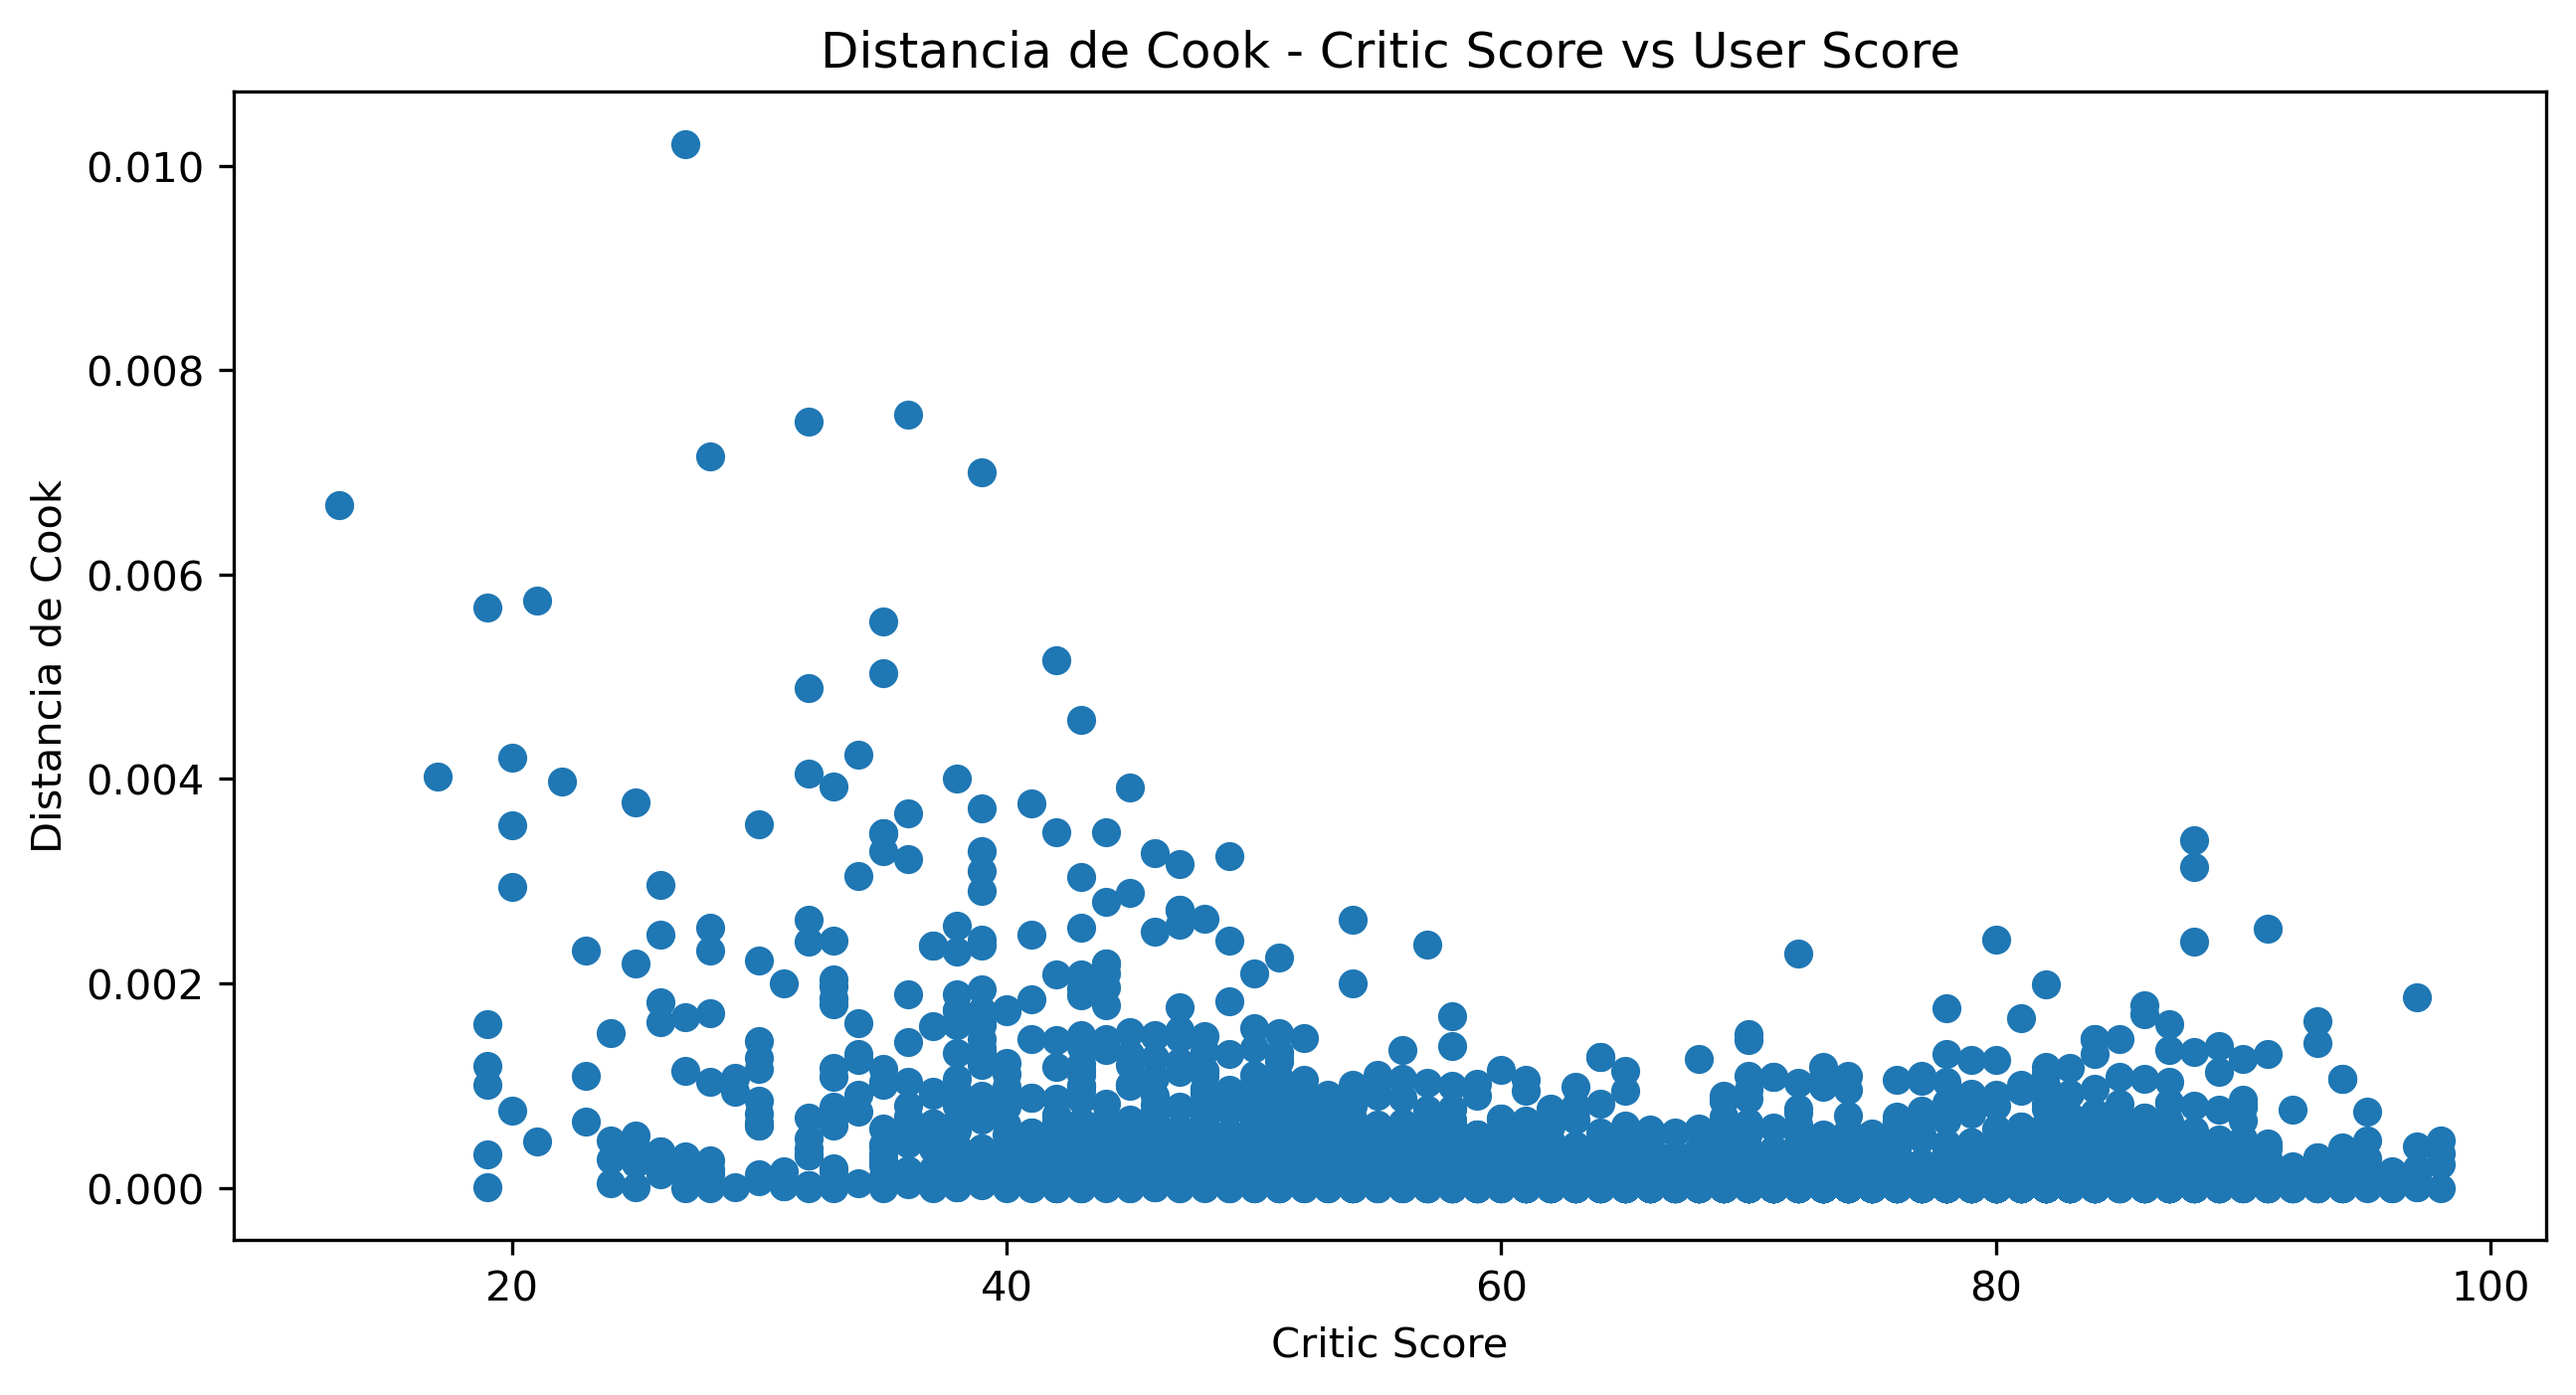

,Global_Sales,Critic_Score,User_Score,Name,Cook
5857,0.30,27.0,8.9,Shrek Swamp Kart Speedway,1.021447e-02
9203,0.14,36.0,0.5,Power Gig: Rise of the SixString,7.567575e-03
13490,0.05,32.0,0.7,Pool Party,7.498537e-03
10793,0.10,28.0,0.9,Dragon Ball: Evolution,7.155991e-03
10318,0.11,39.0,0.5,Charlie and the Chocolate Factory,6.998401e-03
...,...,...,...,...,...
8126,0.18,69.0,7.1,Mega Man X: Command Mission,1.118889e-11
9926,0.12,69.0,7.1,NFL Head Coach,1.118889e-11
2765,0.75,69.0,7.1,Turok,1.118889e-11
14398,0.03,69.0,7.1,MotoGP,1.118889e-11


In [55]:
y = variables['User_Score']
x = sm.add_constant(variables['Critic_Score'])
model = sm.OLS(y, x).fit()

cooks_distance = model.get_influence().cooks_distance[0]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.scatter(variables['Critic_Score'], cooks_distance)
ax.set_xlabel('Critic Score')
ax.set_ylabel("Cook's Distance")
ax.set_title("Cook's Distance - Critic Score vs User Score")
plt.show()

variables_cook_2 = variables.copy()
variables_cook_2['Name'] = data['Name']
variables_cook_2['Cook'] = cooks_distance
variables_cook_2.sort_values(by='Cook', ascending=False)


/Users/gabbi/miniconda3/envs/SaaLab/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7191.
  res = hypotest_fun_out(*samples, **kwds)


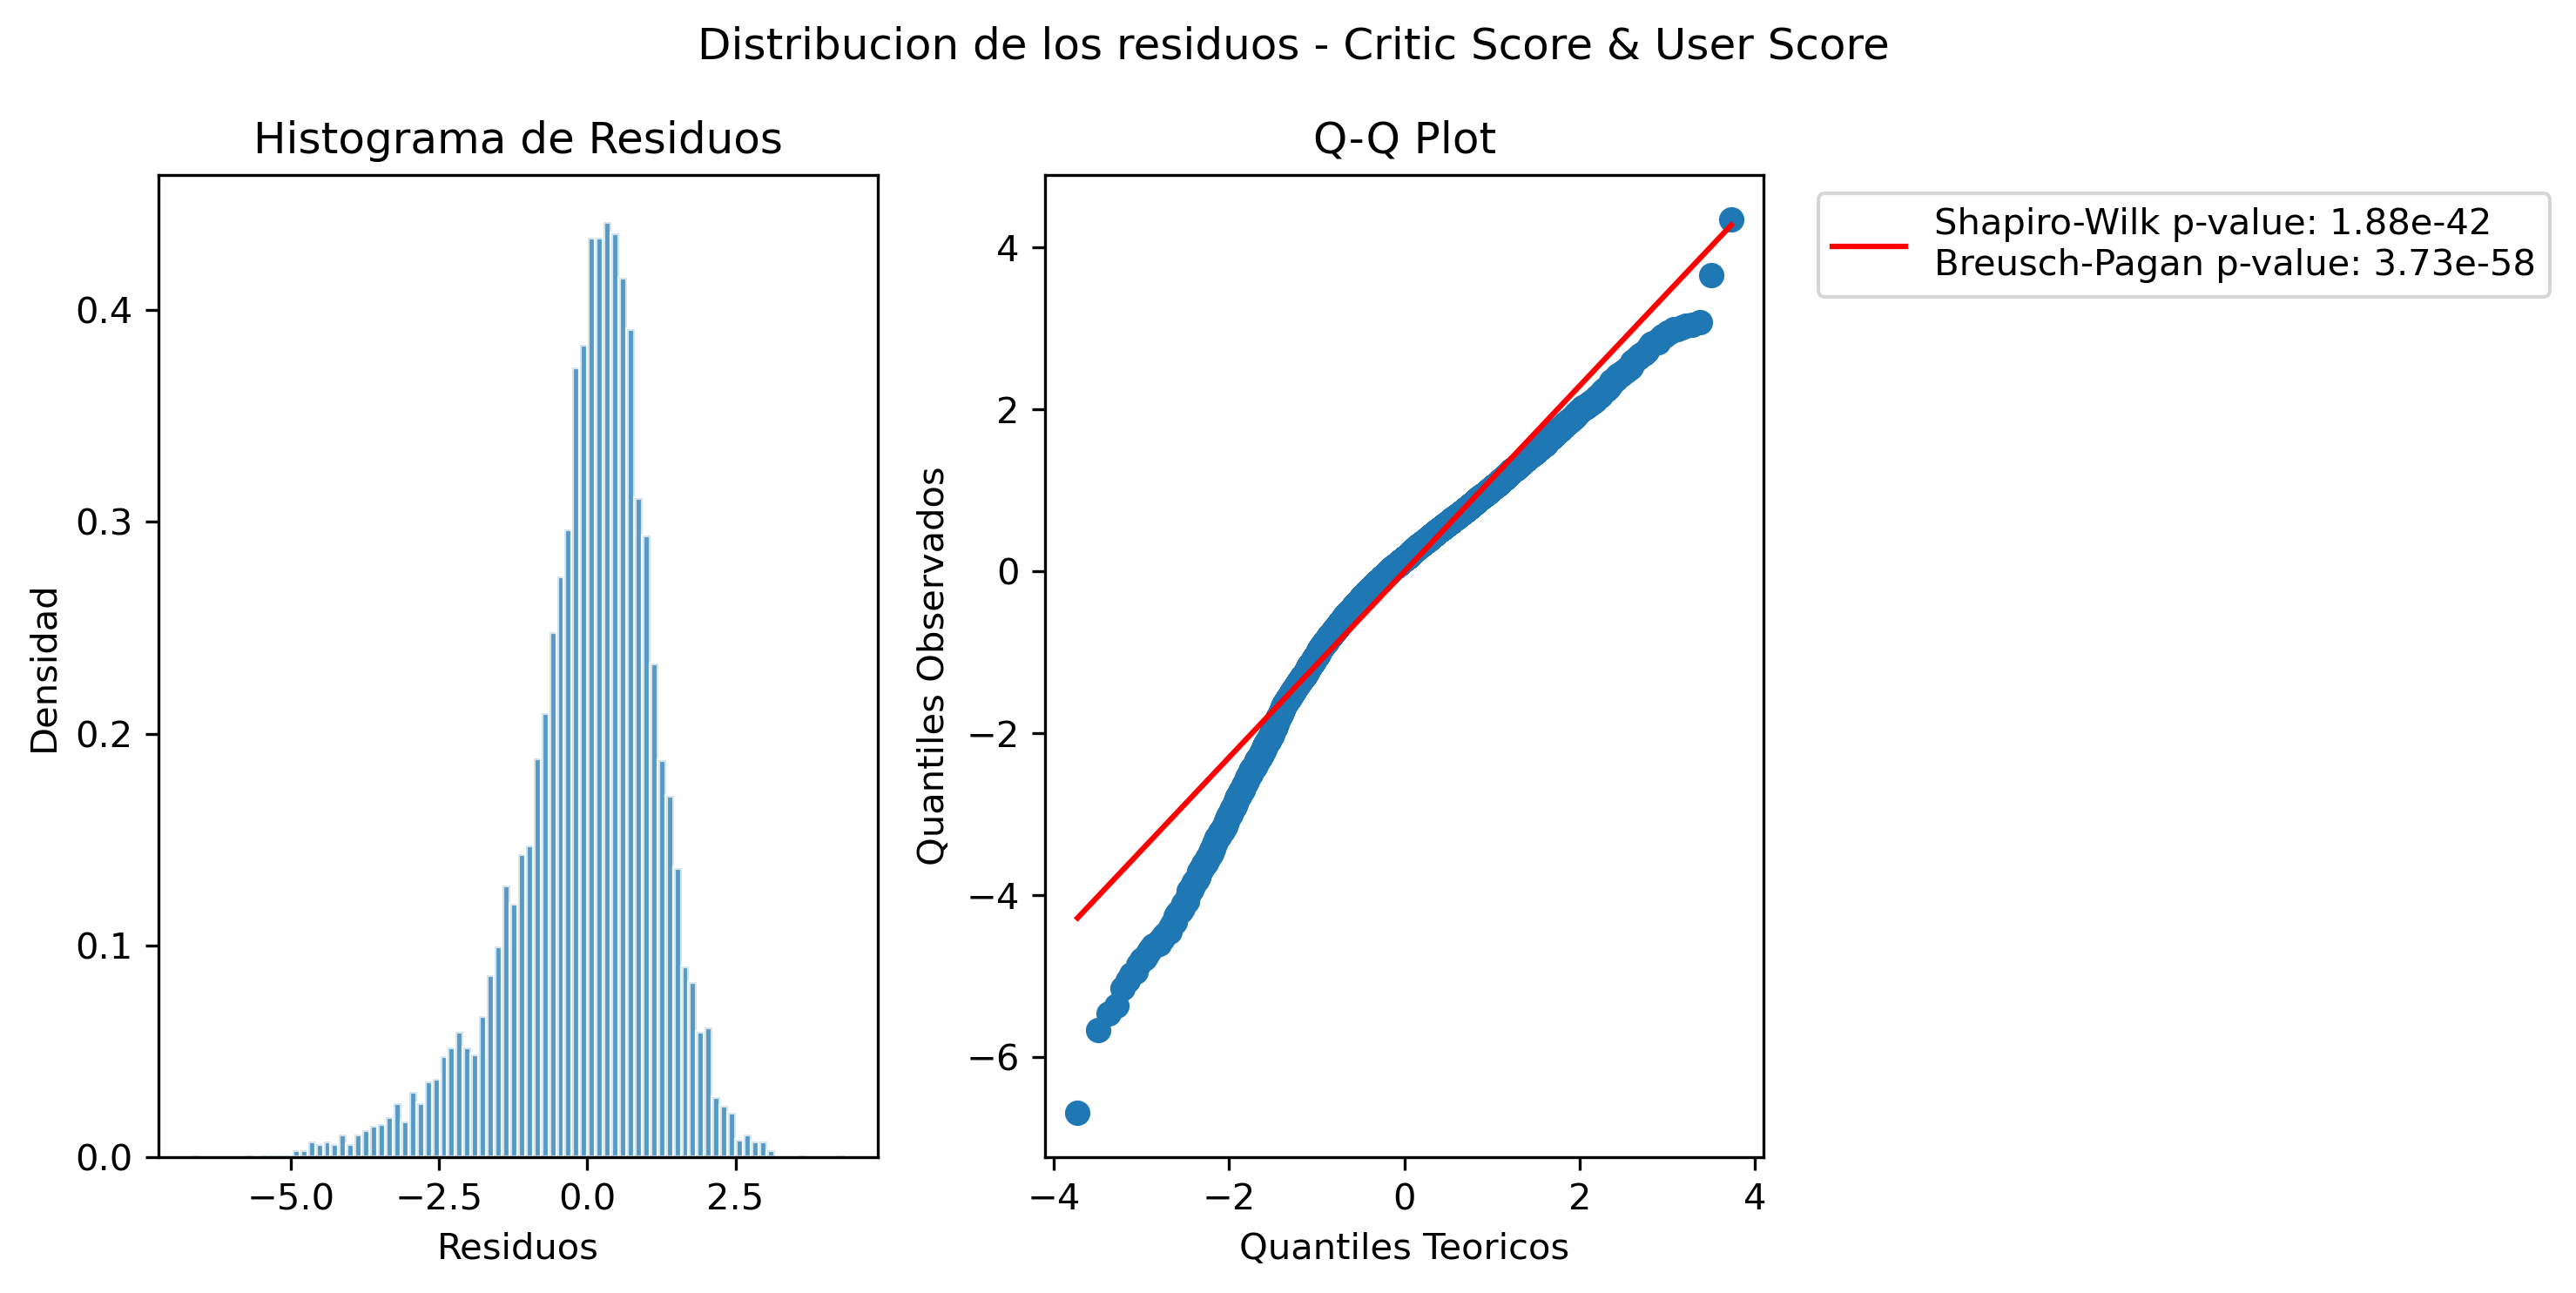

In [56]:
# --- Residuos: Critic_Score -> User_Score ---
y = variables['User_Score']
x = sm.add_constant(variables['Critic_Score'])
model = sm.OLS(y, x).fit()
residuals = model.resid

shapiro_p = st.shapiro(residuals)[1]
_, bp_p, _, _ = het_breuschpagan(residuals, model.model.exog)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].hist(residuals, bins=int(np.sqrt(len(residuals))), density=True, alpha=0.75, edgecolor='white')
ax[0].set_xlabel('Residuos')
ax[0].set_ylabel('Densidad')
ax[0].set_title('Histograma de Residuos')

(osm, osr), (slope, intercept, r) = st.probplot(residuals, dist="norm")
ax[1].scatter(osm, osr)
ax[1].plot(osm, slope * osm + intercept, color='red',
           label=f'Shapiro-Wilk p={shapiro_p:.2e}\nBreusch-Pagan p={bp_p:.2e}')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax[1].set_xlabel('Quantiles Teoricos')
ax[1].set_ylabel('Quantiles Observados')
ax[1].set_title('Q-Q Plot')

fig.suptitle('Residuos - Critic Score & User Score')
plt.tight_layout()
plt.show()


## 9. Transformación Logarítmica

Cuando los supuestos de normalidad y homocedasticidad se violan — como ocurre aquí —
una solución práctica es **transformar la variable de respuesta** antes de ajustar el modelo.

La transformación más común para datos económicos y de conteo es el **logaritmo natural**:
$$
y^* = \\log(1 + y)
$$
(se usa $\\log(1+y)$ en lugar de $\\log(y)$ para manejar el caso $y=0$ sin error.)

Al transformar $y$, el modelo pasa a predecir $\\log(1+\\text{Global\\_Sales})$, que suele
tener una distribución mucho más simétrica y una varianza más estable.

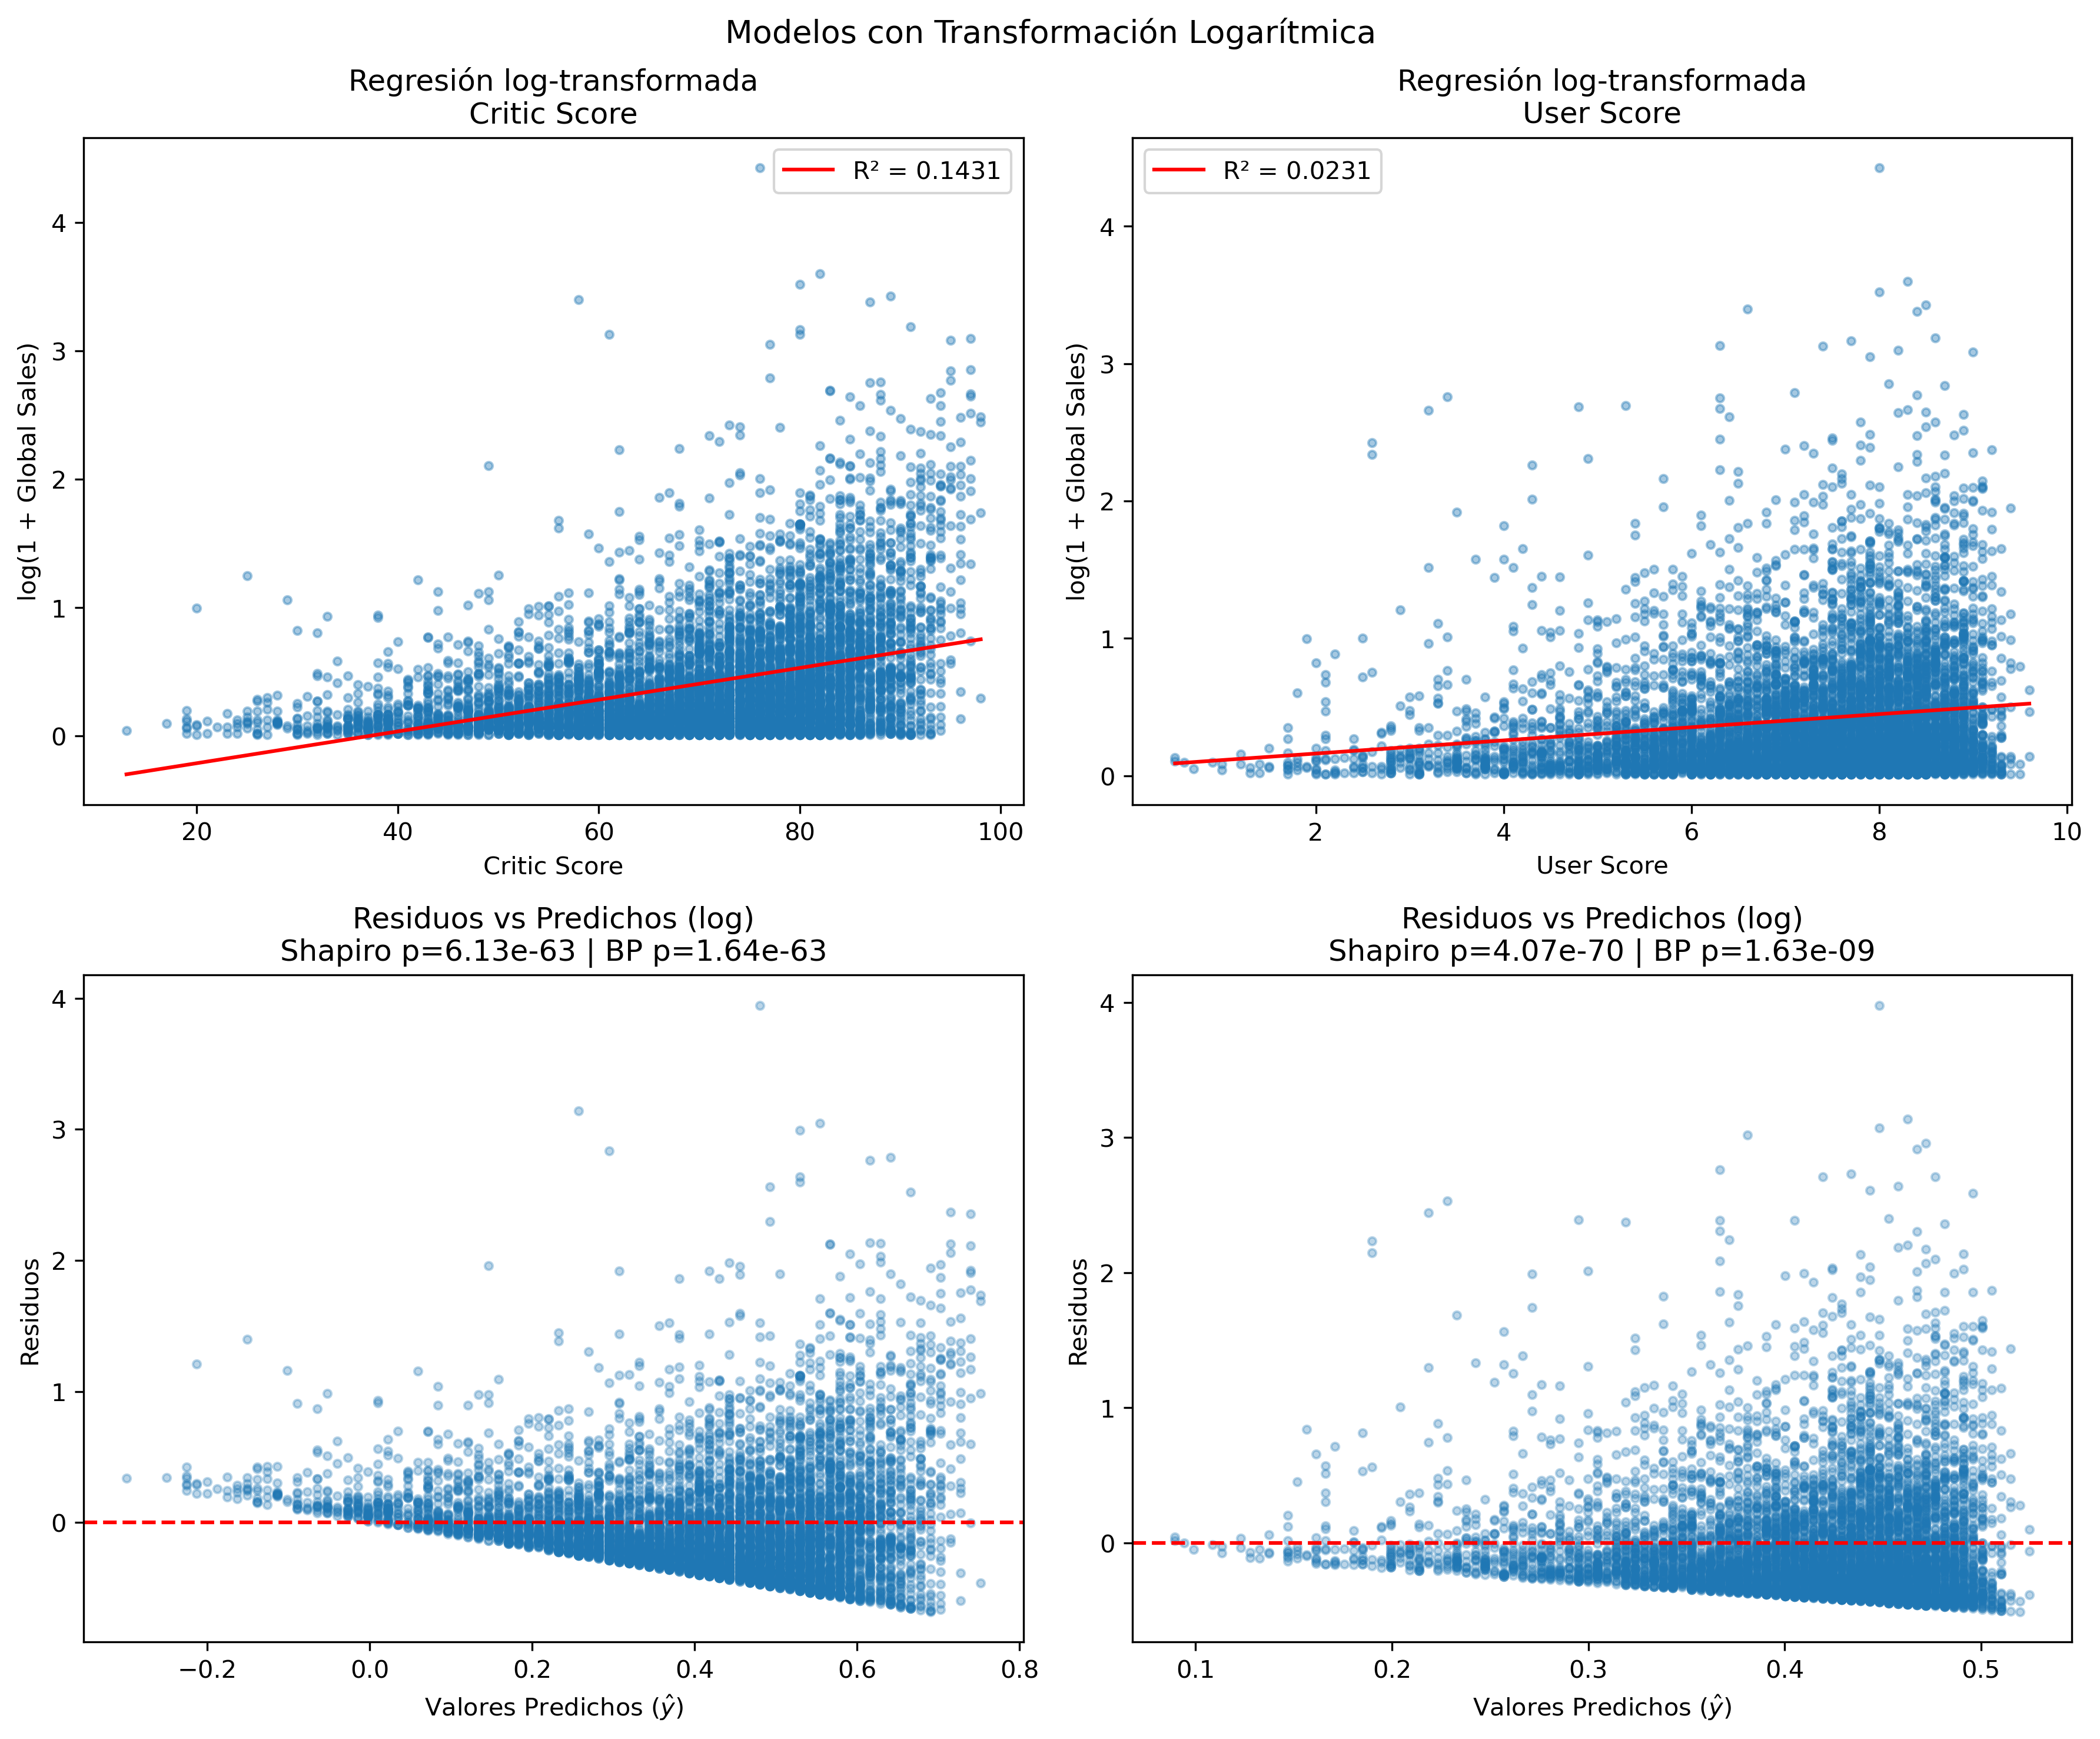


--- Comparación de R² ---
Critic Score     R² original = 0.0561   R² log = 0.1431
User Score       R² original = 0.0078   R² log = 0.0231


In [57]:
variables['log_Sales'] = np.log1p(variables['Global_Sales'])

fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)

for col_idx, (x_col, x_label) in enumerate([('Critic_Score', 'Critic Score'), ('User_Score', 'User Score')]):
    x = sm.add_constant(variables[x_col])
    y = variables['log_Sales']
    model_log = sm.OLS(y, x).fit()

    b0, b1    = model_log.params
    residuals = model_log.resid
    shapiro_p = st.shapiro(residuals)[1]
    _, bp_p, _, _ = het_breuschpagan(residuals, model_log.model.exog)

    ax1 = axes[0][col_idx]
    x_range = np.linspace(variables[x_col].min(), variables[x_col].max(), 200)
    ax1.scatter(variables[x_col], y, alpha=0.4, s=10)
    ax1.plot(x_range, b0 + b1 * x_range, color='red', label=f'R2 = {model_log.rsquared:.4f}')
    ax1.set_xlabel(x_label)
    ax1.set_ylabel('log(1 + Global Sales)')
    ax1.set_title(f'Regresion log\n{x_label}')
    ax1.legend()

    ax2 = axes[1][col_idx]
    ax2.scatter(model_log.fittedvalues, residuals, alpha=0.3, s=10)
    ax2.axhline(0, color='red', linestyle='--')
    ax2.set_xlabel('Valores Predichos')
    ax2.set_ylabel('Residuos')
    ax2.set_title(f'Residuos vs Predichos\nShapiro p={shapiro_p:.2e} | BP p={bp_p:.2e}')

fig.suptitle('Modelos log-transformados', fontsize=13)
plt.tight_layout()
plt.show()

print('\n--- R2 original vs log ---')
for x_col, label in [('Critic_Score', 'Critic Score'), ('User_Score', 'User Score')]:
    x = sm.add_constant(variables[x_col])
    r2_orig = sm.OLS(variables['Global_Sales'], x).fit().rsquared
    r2_log  = sm.OLS(variables['log_Sales'],    x).fit().rsquared
    print(f'{label:15s}  R2 original = {r2_orig:.4f}   R2 log = {r2_log:.4f}')


> **¿Mejoró el modelo?** Compara los R² original vs log-transformado.  
> Aunque R² puede cambiar, lo más importante es que el gráfico de residuos vs predichos
> muestre una dispersión más uniforme y los tests de Shapiro-Wilk y Breusch-Pagan
> entreguen p-values mayores.
>
> Nota: el modelo log-transformado ya no predice ventas directamente, sino
> $\log(1 + \text{ventas})$. Para recuperar la predicción en la escala original
> se aplica la inversa: $\hat{y} = e^{\hat{y}^*} - 1$.

## Síntesis

| Concepto | Qué mide | Cómo calcularlo |
|---|---|---|
| **Correlación de Pearson** $R$ | Fuerza y dirección de relación lineal | `scipy.stats.pearsonr` |
| **Correlación de Spearman** $\rho$ | Relación monotónica (robusta a outliers) | `scipy.stats.spearmanr` |
| **Regresión lineal simple** | Modelo $y = \hat\beta_0 + \hat\beta_1 x$ | Mínimos cuadrados (`statsmodels.OLS`) |
| **R²** | % de varianza de $y$ explicado por el modelo | $R^2 = 1 - SS_E/SS_T$ |
| **Distancia de Cook** | Influencia de cada punto en los coeficientes | `model.get_influence().cooks_distance` |
| **Shapiro-Wilk** | Normalidad de residuos | `scipy.stats.shapiro` |
| **Breusch-Pagan** | Homocedasticidad de residuos | `statsmodels.stats.diagnostic.het_breuschpagan` |
| **Transformación log** | Remedio para sesgo y heterocedasticidad | `np.log1p(y)` |

**Conclusión del caso VideoJuegos**: tanto `Critic_Score` como `User_Score` tienen
correlaciones significativas con `Global_Sales`, pero débiles (R² ≈ 5% y 0.8%).
El puntaje de la crítica explica más varianza que el de los usuarios.
Los supuestos de normalidad y homocedasticidad se violan en la escala original —
la transformación logarítmica mejora ambos diagnósticos.